
# Can Machine Learning Models Know When They Are Wrong?
## An Empirical Study of Confidence, Calibration, Uncertainty Quantification, Distribution Shift, OOD Detection, Selective Prediction, and Conformal Prediction

**Dataset:** CIFAR-10 (in-distribution), CIFAR-100 / SVHN (out-of-distribution), CIFAR-10-C-style corruptions (distribution shift)
**Backbone:** ResNet-18 (trained from scratch on CIFAR-10; no architectural novelty)
**Framework:** PyTorch

---

### What this notebook is

A rigorous *empirical reliability study*, not an accuracy-chasing exercise and not an XAI project. Every experiment answers a version of one question:

> **When the model reports a probability, can that probability be trusted?**

### What was added beyond a standard calibration tutorial

| Area | Standard treatment | This notebook |
|---|---|---|
| Calibration | Temperature scaling only | Temperature, Vector, Matrix scaling, Platt, Histogram Binning, Isotonic Regression, Dirichlet calibration — compared head-to-head |
| Calibration metrics | ECE only | ECE, Adaptive ECE (equal-mass bins), Classwise ECE, Brier score, NLL, Kolmogorov–Smirnov calibration error |
| Uncertainty | MC Dropout only | MC Dropout **+** Deep Ensembles **+** Evidential Deep Learning (Dirichlet/subjective-logic head) — three independent epistemic-uncertainty families compared |
| OOD detection | Softmax confidence only | MSP, Max-logit, Energy score, **ODIN** (temperature + input perturbation), **Mahalanobis distance** in feature space, **k-NN** feature-space OOD |
| Distribution shift | A few corruptions | Full CIFAR-10-C-style corruption suite (noise / blur / weather / digital), 5 severities, following Hendrycks & Dietterich (2019) |
| Decision-making | Selective prediction (accept/abstain) | Selective prediction **+ Conformal Prediction (APS / RAPS)** — the only method here with a *formal statistical coverage guarantee* |
| Rigor | Point-estimate metrics | Bootstrap confidence intervals on every headline metric (ECE, AURC, AUROC) |
| Training-time calibration | — | Label smoothing and Mixup compared as *training-time* alternatives to *post-hoc* calibration |

Everything is built so that a genuinely novel model, GAN, or LLM is never required — only established, well-understood techniques, combined rigorously.

### How to run this

- Set `QUICK_MODE = True` in the Configuration cell for a fast pipeline sanity-check (small data subset, few epochs).
- Set `QUICK_MODE = False` for the full experiment used in the final report.
- GPU strongly recommended for `QUICK_MODE = False` (Colab T4 is enough; ~40–70 min total including the 5-model deep ensemble).



## 1. Research Questions

| # | Question |
|---|---|
| RQ1 | Are softmax confidence scores reliable indicators of correctness? |
| RQ2 | Is the model calibrated — does 80% confidence mean ~80% accuracy? |
| RQ3 | Is the model overconfident on its errors? |
| RQ4 | Do post-hoc calibration methods improve reliability without hurting accuracy? Which method is best? |
| RQ5 | Does confidence degrade appropriately under distribution shift, or does the model stay confidently wrong? |
| RQ6 | Can confidence/uncertainty detect inputs that are entirely out-of-distribution? |
| RQ7 | Does abstaining on low-confidence inputs raise the reliability of accepted predictions? |
| RQ8 | Are MC Dropout, Deep Ensembles, or Evidential Deep Learning better than raw softmax at flagging unreliable predictions? |
| **RQ9 (new)** | Can training-time regularization (label smoothing, Mixup) replace or complement post-hoc calibration? |
| **RQ10 (new)** | Can we obtain prediction sets with a *guaranteed* coverage level via conformal prediction, and how does their size behave under shift/OOD? |

## 2. Hypotheses (to be tested, not assumed)

- **H1** — A high-accuracy ResNet-18 can still be poorly calibrated (likely overconfident).
- **H2** — Confidence on errors is systematically higher than it should be.
- **H3** — Temperature scaling improves ECE substantially with a negligible accuracy change; more flexible post-hoc methods (Dirichlet, isotonic) may do even better but risk overfitting the small validation split.
- **H4** — Under corruption, accuracy drops faster than confidence does — the "confidently wrong" failure mode.
- **H5** — Epistemic-uncertainty methods (MC Dropout / Deep Ensembles / Evidential DL) separate correct-vs-incorrect and ID-vs-OOD better than raw softmax, with Deep Ensembles typically strongest but most expensive.
- **H6** — Selective prediction on calibrated confidence yields a better accuracy–coverage trade-off than on raw confidence.
- **H7 (new)** — Label smoothing / Mixup improves calibration at training time, partially substituting for post-hoc calibration.
- **H8 (new)** — Conformal prediction sets built on calibrated scores are smaller (more efficient) than those built on raw softmax, for the same coverage guarantee, and grow noticeably under distribution shift / OOD — which is itself a valid shift-detection signal.

All hypotheses are falsifiable; the final section reports what the evidence actually shows.


## 3. Environment & Imports

In [1]:

# Core
import os, math, time, random, json, copy, itertools
from dataclasses import dataclass, field, asdict
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
from scipy import stats
from scipy.optimize import minimize

# sklearn (metrics + isotonic + kNN)
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix, precision_recall_fscore_support
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset, TensorDataset
import torchvision
import torchvision.transforms as T
from torchvision.models import resnet18

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("Using device:", DEVICE)


Using device: cpu


## 4. Configuration

Every knob for every experiment lives here. Flip `QUICK_MODE` to switch between a
fast pipeline-sanity-check run and the full experiment.

In [2]:

@dataclass
class Config:
    # ---- Mode ----
    QUICK_MODE: bool = True          # True: small subset, few epochs, fast smoke test
                                      # False: full CIFAR-10, full epochs, final results

    # ---- Reproducibility ----
    SEED: int = 42

    # ---- Data ----
    DATA_ROOT: str = "./data"
    OOD_DATASET: str = "cifar100"    # "cifar100" or "svhn"
    VAL_FRACTION: float = 0.10       # held out from train set: used ONLY for calibration fitting
    CALIB_FRACTION: float = 0.5      # of the held-out val split: half for fitting calibrators, half for evaluating them

    # ---- Model / Training ----
    ARCH: str = "resnet18"
    BATCH_SIZE: int = 32
    EPOCHS_FULL: int = 40
    EPOCHS_QUICK: int = 2
    LR: float = 0.1
    WEIGHT_DECAY: float = 5e-4
    MOMENTUM: float = 0.9
    LABEL_SMOOTHING: float = 0.0     # set >0 (e.g. 0.1) to compare training-time calibration
    USE_MIXUP: bool = False
    MIXUP_ALPHA: float = 0.2
    USE_FOCAL_LOSS: bool = False
    FOCAL_GAMMA: float = 2.0
    DROPOUT_P: float = 0.2           # dropout injected into ResNet-18 for MC-Dropout

    # ---- Deep Ensemble ----
    ENSEMBLE_SIZE_FULL: int = 5
    ENSEMBLE_SIZE_QUICK: int = 2

    # ---- MC Dropout ----
    MC_SAMPLES: int = 30

    # ---- Calibration ----
    N_BINS_ECE: int = 15

    # ---- Corruptions (CIFAR-10-C style) ----
    CORRUPTIONS: tuple = ("gaussian_noise", "shot_noise", "impulse_noise",
                           "defocus_blur", "motion_blur", "gaussian_blur",
                           "brightness", "contrast", "jpeg_compression",
                           "pixelate", "fog", "frost")
    SEVERITIES: tuple = (1, 2, 3, 4, 5)

    # ---- Selective prediction / conformal ----
    THRESHOLDS: tuple = tuple(np.round(np.arange(0.0, 1.0, 0.02), 2))
    CONFORMAL_ALPHA: float = 0.10    # 90% target coverage

    # ---- Bootstrap ----
    N_BOOTSTRAP: int = 1000

    @property
    def EPOCHS(self):
        return self.EPOCHS_QUICK if self.QUICK_MODE else self.EPOCHS_FULL

    @property
    def ENSEMBLE_SIZE(self):
        return self.ENSEMBLE_SIZE_QUICK if self.QUICK_MODE else self.ENSEMBLE_SIZE_FULL

    @property
    def TRAIN_SUBSET_SIZE(self):
        return 4000 if self.QUICK_MODE else None   # None = full 50k

    @property
    def TEST_SUBSET_SIZE(self):
        return 1000 if self.QUICK_MODE else None   # None = full 10k

cfg = Config()
print(json.dumps({k: v for k, v in asdict(cfg).items()}, indent=2, default=str))


{
  "QUICK_MODE": true,
  "SEED": 42,
  "DATA_ROOT": "./data",
  "OOD_DATASET": "cifar100",
  "VAL_FRACTION": 0.1,
  "CALIB_FRACTION": 0.5,
  "ARCH": "resnet18",
  "BATCH_SIZE": 32,
  "EPOCHS_FULL": 40,
  "EPOCHS_QUICK": 2,
  "LR": 0.1,
  "WEIGHT_DECAY": 0.0005,
  "MOMENTUM": 0.9,
  "LABEL_SMOOTHING": 0.0,
  "USE_MIXUP": false,
  "MIXUP_ALPHA": 0.2,
  "USE_FOCAL_LOSS": false,
  "FOCAL_GAMMA": 2.0,
  "DROPOUT_P": 0.2,
  "ENSEMBLE_SIZE_FULL": 5,
  "ENSEMBLE_SIZE_QUICK": 2,
  "MC_SAMPLES": 30,
  "N_BINS_ECE": 15,
  "CORRUPTIONS": [
    "gaussian_noise",
    "shot_noise",
    "impulse_noise",
    "defocus_blur",
    "motion_blur",
    "gaussian_blur",
    "brightness",
    "contrast",
    "jpeg_compression",
    "pixelate",
    "fog",
    "frost"
  ],
  "SEVERITIES": [
    1,
    2,
    3,
    4,
    5
  ],
  "THRESHOLDS": [
    0.0,
    0.02,
    0.04,
    0.06,
    0.08,
    0.1,
    0.12,
    0.14,
    0.16,
    0.18,
    0.2,
    0.22,
    0.24,
    0.26,
    0.28,
    0.3,
    0.32,
 

## 5. Reproducibility

In [3]:

def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(cfg.SEED)


## 6. Dataset Preparation

- **In-distribution:** CIFAR-10 (10 classes, 32×32 RGB).
- **Calibration split:** a slice of the training set is held out and *never used for training* —
  half of it fits post-hoc calibrators, the other half evaluates them, keeping the test set
  fully untouched until final evaluation (avoids optimistic bias).
- **OOD dataset:** CIFAR-100 (default) or SVHN — never seen during training, used only in
  Experiment 6 (OOD detection).
- **Corruption suite:** implemented from scratch (no external corruption package needed, so it
  works even without a `common-corruptions` install) covering noise / blur / weather / digital
  corruption families at 5 severities each, following the design of Hendrycks & Dietterich (2019),
  *Benchmarking Neural Network Robustness to Common Corruptions and Perturbations*.


In [4]:

CIFAR10_CLASSES = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']

MEAN = (0.4914, 0.4822, 0.4465)
STD  = (0.2470, 0.2435, 0.2616)

train_tf = T.Compose([
    T.RandomCrop(32, padding=4),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])
eval_tf = T.Compose([
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

full_train = torchvision.datasets.CIFAR10(cfg.DATA_ROOT, train=True, download=True, transform=train_tf)
full_train_eval = torchvision.datasets.CIFAR10(cfg.DATA_ROOT, train=True, download=True, transform=eval_tf)
test_set  = torchvision.datasets.CIFAR10(cfg.DATA_ROOT, train=False, download=True, transform=eval_tf)

n_total = len(full_train)
idx = np.arange(n_total)
rng = np.random.RandomState(cfg.SEED)
rng.shuffle(idx)

n_val = int(cfg.VAL_FRACTION * n_total)
val_idx, train_idx = idx[:n_val], idx[n_val:]

if cfg.TRAIN_SUBSET_SIZE is not None:
    train_idx = train_idx[:cfg.TRAIN_SUBSET_SIZE]
    val_idx = val_idx[:max(200, cfg.TRAIN_SUBSET_SIZE // 10)]

n_calib_fit = int(cfg.CALIB_FRACTION * len(val_idx))
calibfit_idx, calibeval_idx = val_idx[:n_calib_fit], val_idx[n_calib_fit:]

train_dataset = Subset(full_train, train_idx)
calibfit_dataset = Subset(full_train_eval, calibfit_idx)   # fit calibrators (temp scaling, isotonic, ...)
calibeval_dataset = Subset(full_train_eval, calibeval_idx) # evaluate calibrators pre-test

if cfg.TEST_SUBSET_SIZE is not None:
    test_idx = np.arange(len(test_set))[:cfg.TEST_SUBSET_SIZE]
    test_dataset = Subset(test_set, test_idx)
else:
    test_dataset = test_set

train_loader     = DataLoader(train_dataset, batch_size=cfg.BATCH_SIZE, shuffle=True,  num_workers=0, drop_last=True)
calibfit_loader  = DataLoader(calibfit_dataset, batch_size=cfg.BATCH_SIZE, shuffle=False, num_workers=0)
calibeval_loader = DataLoader(calibeval_dataset, batch_size=cfg.BATCH_SIZE, shuffle=False, num_workers=0)
test_loader      = DataLoader(test_dataset, batch_size=cfg.BATCH_SIZE, shuffle=False, num_workers=0)

print(f"train={len(train_dataset)}  calib_fit={len(calibfit_dataset)}  "
      f"calib_eval={len(calibeval_dataset)}  test={len(test_dataset)}")


100.0%


train=4000  calib_fit=200  calib_eval=200  test=1000


In [5]:

# ---- OOD dataset ----
if cfg.OOD_DATASET == "cifar100":
    ood_raw = torchvision.datasets.CIFAR100(cfg.DATA_ROOT, train=False, download=True, transform=eval_tf)
else:
    ood_raw = torchvision.datasets.SVHN(cfg.DATA_ROOT, split="test", download=True, transform=eval_tf)

if cfg.TEST_SUBSET_SIZE is not None:
    ood_idx = np.arange(len(ood_raw))[:cfg.TEST_SUBSET_SIZE]
    ood_dataset = Subset(ood_raw, ood_idx)
else:
    ood_dataset = ood_raw

ood_loader = DataLoader(ood_dataset, batch_size=256, shuffle=False, num_workers=2)
print(f"OOD dataset ({cfg.OOD_DATASET}): {len(ood_dataset)} samples")


100.0%


OOD dataset (cifar100): 1000 samples


### 6.1 Corruption library (distribution-shift generators)

In [6]:

def _clip(img):
    return np.clip(img, 0, 1)

def gaussian_noise(x, severity):
    c = [0.03, 0.06, 0.09, 0.15, 0.20][severity - 1]
    return _clip(x + np.random.normal(size=x.shape, scale=c))

def shot_noise(x, severity):
    c = [60, 25, 12, 5, 3][severity - 1]
    return _clip(np.random.poisson(x * c) / c)

def impulse_noise(x, severity):
    c = [0.01, 0.02, 0.05, 0.08, 0.14][severity - 1]
    out = x.copy()
    mask = np.random.rand(*x.shape[:2]) < c
    salt = np.random.rand(*x.shape[:2]) < 0.5
    out[mask & salt] = 1.0
    out[mask & ~salt] = 0.0
    return _clip(out)

def gaussian_blur(x, severity):
    from scipy.ndimage import gaussian_filter
    c = [0.4, 0.6, 0.8, 1.0, 1.4][severity - 1]
    out = np.stack([gaussian_filter(x[..., ch], sigma=c) for ch in range(x.shape[-1])], axis=-1)
    return _clip(out)

def defocus_blur(x, severity):
    # approximated with a slightly stronger gaussian blur (disk-blur substitute, dependency-free)
    from scipy.ndimage import gaussian_filter
    c = [0.5, 0.8, 1.1, 1.5, 2.0][severity - 1]
    out = np.stack([gaussian_filter(x[..., ch], sigma=c) for ch in range(x.shape[-1])], axis=-1)
    return _clip(out)

def motion_blur(x, severity):
    c = [3, 5, 7, 9, 12][severity - 1]
    kernel = np.zeros((c, c)); kernel[c // 2, :] = 1.0 / c
    from scipy.signal import convolve2d
    out = np.stack([convolve2d(x[..., ch], kernel, mode="same", boundary="symm") for ch in range(x.shape[-1])], axis=-1)
    return _clip(out)

def brightness(x, severity):
    c = [0.1, 0.2, 0.3, 0.4, 0.5][severity - 1]
    return _clip(x + c)

def contrast(x, severity):
    c = [0.75, 0.6, 0.45, 0.3, 0.15][severity - 1]
    mean = x.mean(axis=(0, 1), keepdims=True)
    return _clip((x - mean) * c + mean)

def jpeg_compression(x, severity):
    import io
    from PIL import Image
    c = [80, 65, 45, 25, 10][severity - 1]
    img = Image.fromarray((x * 255).astype(np.uint8))
    buf = io.BytesIO(); img.save(buf, format="JPEG", quality=c)
    buf.seek(0)
    return np.asarray(Image.open(buf)).astype(np.float32) / 255.0

def pixelate(x, severity):
    from PIL import Image
    c = [0.9, 0.75, 0.6, 0.45, 0.3][severity - 1]
    h, w = x.shape[:2]
    img = Image.fromarray((x * 255).astype(np.uint8))
    img = img.resize((max(1, int(w * c)), max(1, int(h * c))), Image.BOX)
    img = img.resize((w, h), Image.NEAREST)
    return np.asarray(img).astype(np.float32) / 255.0

def fog(x, severity):
    c = [(0.2, 3), (0.5, 3), (0.75, 2.5), (1.0, 2), (1.5, 1.75)][severity - 1]
    h, w = x.shape[:2]
    yy, xx = np.mgrid[0:h, 0:w]
    fog_layer = (np.sin(xx / c[1]) + np.cos(yy / c[1])) / 2 * c[0]
    fog_layer = (fog_layer - fog_layer.min()) / (fog_layer.max() - fog_layer.min() + 1e-8)
    out = x * (1 - c[0]) + fog_layer[..., None] * c[0]
    return _clip(out)

def frost(x, severity):
    c = [0.15, 0.25, 0.35, 0.45, 0.55][severity - 1]
    noise = np.random.rand(*x.shape[:2])[..., None]
    return _clip(x * (1 - c) + noise * c)

CORRUPTION_FNS = {
    "gaussian_noise": gaussian_noise, "shot_noise": shot_noise, "impulse_noise": impulse_noise,
    "defocus_blur": defocus_blur, "motion_blur": motion_blur, "gaussian_blur": gaussian_blur,
    "brightness": brightness, "contrast": contrast, "jpeg_compression": jpeg_compression,
    "pixelate": pixelate, "fog": fog, "frost": frost,
}

class CorruptedCIFAR10(torch.utils.data.Dataset):
    """Applies a named corruption at a given severity to CIFAR-10 test images on the fly."""
    def __init__(self, base_dataset_pil, corruption_name, severity, normalize=True):
        self.base = base_dataset_pil          # torchvision CIFAR10 with transform=None (PIL images)
        self.fn = CORRUPTION_FNS[corruption_name]
        self.severity = severity
        self.to_tensor = T.ToTensor()
        self.normalize = T.Normalize(MEAN, STD) if normalize else None

    def __len__(self):
        return len(self.base)

    def __getitem__(self, i):
        img, label = self.base[i]
        x = np.asarray(img).astype(np.float32) / 255.0
        x = self.fn(x, self.severity)
        x = torch.from_numpy(x.astype(np.float32)).permute(2, 0, 1)
        if self.normalize is not None:
            x = self.normalize(x)
        return x, label

test_set_pil = torchvision.datasets.CIFAR10(cfg.DATA_ROOT, train=False, download=True, transform=None)
if cfg.TEST_SUBSET_SIZE is not None:
    test_set_pil = Subset(test_set_pil, test_idx)

print(f"{len(CORRUPTION_FNS)} corruption functions implemented:", list(CORRUPTION_FNS.keys()))


12 corruption functions implemented: ['gaussian_noise', 'shot_noise', 'impulse_noise', 'defocus_blur', 'motion_blur', 'gaussian_blur', 'brightness', 'contrast', 'jpeg_compression', 'pixelate', 'fog', 'frost']


## 7. Data Visualization

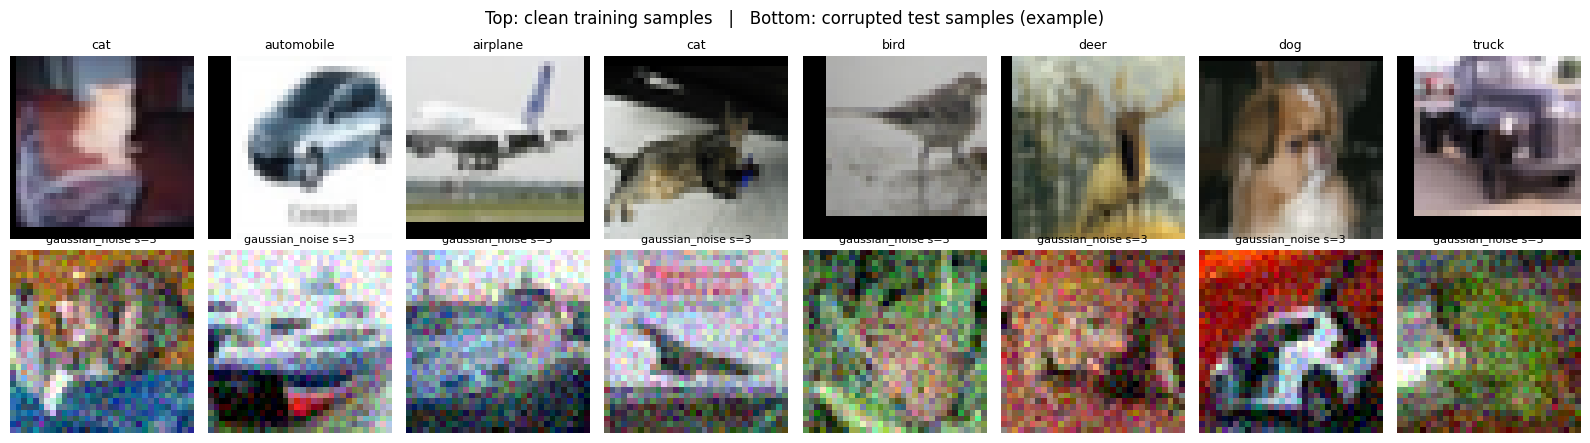

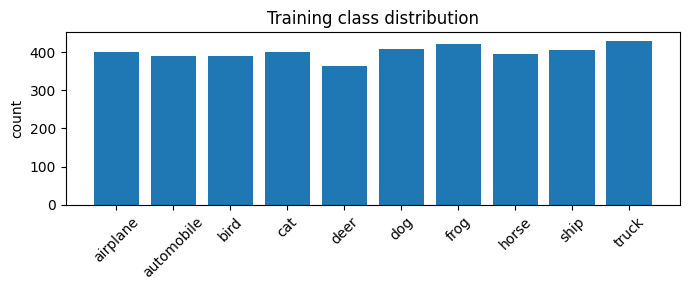

In [7]:

def denorm(t):
    t = t.clone()
    for c in range(3):
        t[c] = t[c] * STD[c] + MEAN[c]
    return t.clamp(0, 1)

fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for i in range(8):
    img, label = train_dataset[i]
    axes[0, i].imshow(denorm(img).permute(1, 2, 0)); axes[0, i].set_title(CIFAR10_CLASSES[label], fontsize=9); axes[0, i].axis("off")
for i in range(8):
    raw_img, label = test_set_pil[i] if not isinstance(test_set_pil, Subset) else test_set_pil.dataset[test_set_pil.indices[i]]
    x = np.asarray(raw_img).astype(np.float32) / 255.0
    x_c = gaussian_noise(x, severity=3)
    axes[1, i].imshow(x_c); axes[1, i].set_title("gaussian_noise s=3", fontsize=8); axes[1, i].axis("off")
plt.suptitle("Top: clean training samples   |   Bottom: corrupted test samples (example)")
plt.tight_layout(); plt.show()

labels = [full_train.targets[i] for i in train_idx]
plt.figure(figsize=(7, 3))
plt.bar(CIFAR10_CLASSES, np.bincount(labels, minlength=10))
plt.xticks(rotation=45); plt.ylabel("count"); plt.title("Training class distribution"); plt.tight_layout(); plt.show()


## 8. Model Definition

Standard **ResNet-18**, adapted for 32×32 CIFAR-style input (3×3 stem, no initial max-pool —
the standard "CIFAR ResNet" adaptation, not an architectural invention). Three thin variants
of the *same* backbone are used across experiments:

1. **Deterministic head** — standard softmax classifier (baseline + calibration + OOD experiments).
2. **MC-Dropout head** — dropout layers inserted before the final FC layer, kept active at test time.
3. **Evidential head** — outputs Dirichlet concentration parameters instead of softmax logits
   (Sensoy et al., 2018, *Evidential Deep Learning to Quantify Classification Uncertainty*),
   giving a closed-form epistemic-uncertainty estimate from a single forward pass.

No new architecture is invented — only well-established output heads on top of ResNet-18.


In [8]:

def make_cifar_resnet18(num_classes=10, dropout_p=0.0):
    model = resnet18(weights=None, num_classes=num_classes)
    model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
    model.maxpool = nn.Identity()
    if dropout_p > 0:
        in_features = model.fc.in_features
        model.fc = nn.Sequential(nn.Dropout(p=dropout_p), nn.Linear(in_features, num_classes))
    return model

class EvidentialResNet18(nn.Module):
    """Same backbone; final layer outputs non-negative evidence e_k >= 0 per class.
    Dirichlet parameters alpha_k = e_k + 1. Belief mass, uncertainty mass, and expected
    probability all fall out in closed form (Sensoy et al. 2018)."""
    def __init__(self, num_classes=10):
        super().__init__()
        backbone = resnet18(weights=None, num_classes=num_classes)
        backbone.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        backbone.maxpool = nn.Identity()
        self.features = nn.Sequential(*list(backbone.children())[:-1])
        self.fc = nn.Linear(backbone.fc.in_features, num_classes)
        self.num_classes = num_classes

    def forward(self, x):
        h = self.features(x).flatten(1)
        logits = self.fc(h)
        evidence = F.softplus(logits)          # evidence >= 0
        alpha = evidence + 1.0                  # Dirichlet concentration
        return alpha

    @staticmethod
    def uncertainty_and_prob(alpha):
        S = alpha.sum(dim=1, keepdim=True)                 # Dirichlet strength
        prob = alpha / S                                    # expected probability (mean of Dirichlet)
        K = alpha.shape[1]
        uncertainty = K / S.squeeze(1)                       # vacuity / epistemic uncertainty in [0,1]
        return prob, uncertainty

def get_feature_extractor(model):
    """Returns a function mapping images -> penultimate-layer features (for Mahalanobis/kNN OOD)."""
    modules = list(model.children())
    feat_net = nn.Sequential(*modules[:-1]).to(DEVICE).eval()
    def extract(x):
        with torch.no_grad():
            f = feat_net(x)
            return f.flatten(1)
    return extract


## 9. Loss Functions

Standard cross-entropy is the default. Two well-known *training-time* calibration
alternatives are implemented for RQ9 / H7 (compared against post-hoc calibration later,
not as a replacement for it):

- **Label smoothing** — softens one-hot targets, empirically improves calibration (Müller et al., 2019).
- **Mixup** — convex combination of input/label pairs (Zhang et al., 2018), also known to improve calibration.
- **Focal loss** — down-weights easy examples; included as it is the loss used in Mukhoti et al. (2020),
  *Calibrating Deep Neural Networks using Focal Loss*, shown to directly reduce ECE.


In [9]:

def focal_loss(logits, targets, gamma=2.0):
    logp = F.log_softmax(logits, dim=1)
    p = logp.exp()
    logp_t = logp.gather(1, targets.unsqueeze(1)).squeeze(1)
    p_t = p.gather(1, targets.unsqueeze(1)).squeeze(1)
    loss = -((1 - p_t) ** gamma) * logp_t
    return loss.mean()

def mixup_data(x, y, alpha=0.2):
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1.0
    idx = torch.randperm(x.size(0), device=x.device)
    mixed_x = lam * x + (1 - lam) * x[idx]
    return mixed_x, y, y[idx], lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

def evidential_loss(alpha, targets_onehot, epoch, annealing_epochs=10):
    """Type-II MLE Dirichlet loss + KL regularizer that anneals in over training (Sensoy et al. 2018)."""
    S = alpha.sum(dim=1, keepdim=True)
    mse = ((targets_onehot - alpha / S) ** 2).sum(dim=1)
    var = (alpha * (S - alpha) / (S * S * (S + 1))).sum(dim=1)
    likelihood = (mse + var).mean()
    alpha_tilde = targets_onehot + (1 - targets_onehot) * alpha
    K = alpha.shape[1]
    S_tilde = alpha_tilde.sum(dim=1, keepdim=True)
    kl = (torch.lgamma(S_tilde) - torch.lgamma(torch.tensor(float(K))).to(alpha.device)
          - torch.lgamma(alpha_tilde).sum(dim=1, keepdim=True)
          + ((alpha_tilde - 1) * (torch.digamma(alpha_tilde) - torch.digamma(S_tilde))).sum(dim=1, keepdim=True))
    annealing_coef = min(1.0, epoch / annealing_epochs)
    return likelihood + annealing_coef * kl.mean()


## 10. Training

In [10]:

def train_model(model, loader, epochs, lr=cfg.LR, wd=cfg.WEIGHT_DECAY, momentum=cfg.MOMENTUM,
                 label_smoothing=0.0, use_mixup=False, mixup_alpha=0.2, use_focal=False,
                 evidential=False, log_every=1, tag="model"):
    model.to(DEVICE)
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=momentum, weight_decay=wd, nesterov=True)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(1, epochs))
    ce = nn.CrossEntropyLoss(label_smoothing=label_smoothing)

    history = {"train_loss": [], "train_acc": []}
    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()

            if evidential:
                y_onehot = F.one_hot(y, num_classes=10).float()
                alpha = model(x)
                loss = evidential_loss(alpha, y_onehot, epoch)
                preds = alpha.argmax(dim=1)
            elif use_mixup:
                mx, ya, yb, lam = mixup_data(x, y, mixup_alpha)
                logits = model(mx)
                loss = mixup_criterion(ce, logits, ya, yb, lam)
                preds = logits.argmax(dim=1)
            elif use_focal:
                logits = model(x)
                loss = focal_loss(logits, y, gamma=cfg.FOCAL_GAMMA)
                preds = logits.argmax(dim=1)
            else:
                logits = model(x)
                loss = ce(logits, y)
                preds = logits.argmax(dim=1)

            loss.backward()
            opt.step()

            running_loss += loss.item() * x.size(0)
            correct += (preds == y).sum().item()
            total += x.size(0)
        sched.step()
        ep_loss, ep_acc = running_loss / total, correct / total
        history["train_loss"].append(ep_loss); history["train_acc"].append(ep_acc)
        if epoch % log_every == 0 or epoch == epochs - 1:
            print(f"[{tag}] epoch {epoch+1}/{epochs}  loss={ep_loss:.4f}  acc={ep_acc:.4f}")
    return history

# ---- Train the baseline deterministic model ----
baseline_model = make_cifar_resnet18(num_classes=10, dropout_p=0.0)
t0 = time.time()
history_baseline = train_model(baseline_model, train_loader, epochs=cfg.EPOCHS,
                                label_smoothing=cfg.LABEL_SMOOTHING, use_mixup=cfg.USE_MIXUP,
                                mixup_alpha=cfg.MIXUP_ALPHA, use_focal=cfg.USE_FOCAL_LOSS,
                                tag="baseline")
print(f"Baseline training took {time.time()-t0:.1f}s")


[baseline] epoch 1/2  loss=3.2277  acc=0.1285
[baseline] epoch 2/2  loss=2.1273  acc=0.2005
Baseline training took 472.3s


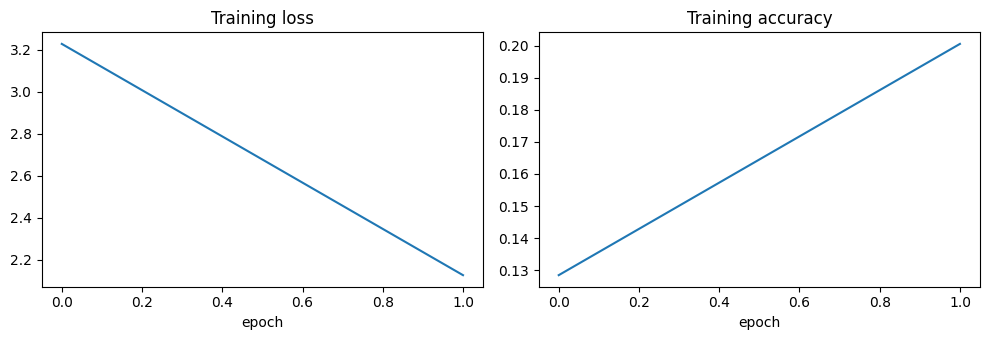

In [11]:

plt.figure(figsize=(10,3.5))
plt.subplot(1,2,1); plt.plot(history_baseline["train_loss"]); plt.title("Training loss"); plt.xlabel("epoch")
plt.subplot(1,2,2); plt.plot(history_baseline["train_acc"]); plt.title("Training accuracy"); plt.xlabel("epoch")
plt.tight_layout(); plt.show()


## 11. Baseline Evaluation

Test Accuracy: 0.2540
Macro Precision: 0.2425
Macro Recall: 0.2401
Macro F1: 0.1863


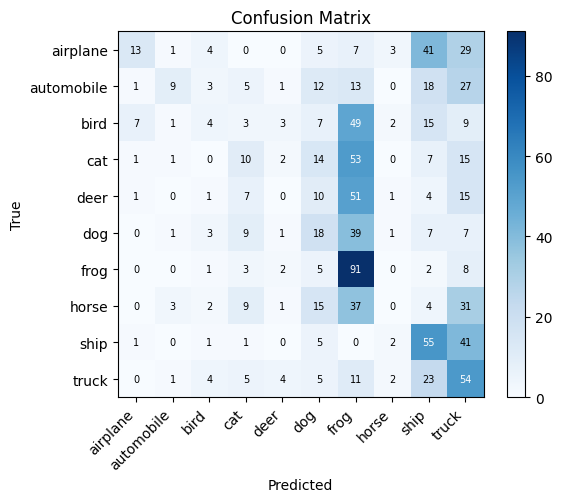

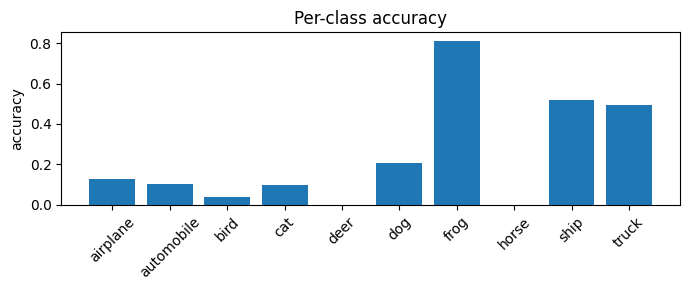

In [12]:

@torch.no_grad()
def get_logits_labels(model, loader, evidential=False):
    model.eval().to(DEVICE)
    all_logits, all_labels = [], []
    for x, y in loader:
        x = x.to(DEVICE)
        out = model(x)
        all_logits.append(out.cpu())
        all_labels.append(y)
    return torch.cat(all_logits), torch.cat(all_labels)

test_logits, test_labels = get_logits_labels(baseline_model, test_loader)
test_probs = F.softmax(test_logits, dim=1).numpy()
test_preds = test_probs.argmax(axis=1)
test_labels_np = test_labels.numpy()

acc = (test_preds == test_labels_np).mean()
prec, rec, f1, _ = precision_recall_fscore_support(test_labels_np, test_preds, average="macro", zero_division=0)
print(f"Test Accuracy: {acc:.4f}\nMacro Precision: {prec:.4f}\nMacro Recall: {rec:.4f}\nMacro F1: {f1:.4f}")

cm = confusion_matrix(test_labels_np, test_preds)
fig, ax = plt.subplots(figsize=(6,5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10)); ax.set_xticklabels(CIFAR10_CLASSES, rotation=45, ha="right")
ax.set_yticks(range(10)); ax.set_yticklabels(CIFAR10_CLASSES)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Confusion Matrix")
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                 color="white" if cm[i, j] > cm.max()/2 else "black")
plt.colorbar(im); plt.tight_layout(); plt.show()

per_class_acc = cm.diagonal() / cm.sum(axis=1)
plt.figure(figsize=(7,3))
plt.bar(CIFAR10_CLASSES, per_class_acc); plt.xticks(rotation=45); plt.ylabel("accuracy")
plt.title("Per-class accuracy"); plt.tight_layout(); plt.show()


## 12. Prediction & Confidence Extraction

This table is reused throughout the notebook.

In [13]:

pred_table = pd.DataFrame({
    "sample_id": np.arange(len(test_labels_np)),
    "true_class": test_labels_np,
    "predicted_class": test_preds,
    "confidence": test_probs.max(axis=1),
    "correct": (test_preds == test_labels_np).astype(int),
})
for k in range(10):
    pred_table[f"prob_{CIFAR10_CLASSES[k]}"] = test_probs[:, k]

pred_table.head()


,sample_id,true_class,predicted_class,confidence,correct,prob_airplane,prob_automobile,prob_bird,prob_cat,prob_deer,prob_dog,prob_frog,prob_horse,prob_ship,prob_truck
0,0,3,3,0.151383,1,0.026907,0.074084,0.146382,0.151383,0.143324,0.126500,0.128316,0.117887,0.029887,0.055329
1,1,8,8,0.234596,1,0.189428,0.202902,0.082734,0.034927,0.019412,0.028719,0.007815,0.046544,0.234596,0.152924
2,2,8,8,0.237145,1,0.160548,0.169133,0.078488,0.043410,0.021017,0.035532,0.008874,0.061805,0.237145,0.184048
3,3,0,8,0.225473,0,0.151736,0.166927,0.079982,0.055697,0.025100,0.037657,0.011979,0.069051,0.225473,0.176400
4,4,6,6,0.268195,1,0.003588,0.026706,0.124414,0.151090,0.223486,0.094396,0.268195,0.090111,0.003601,0.014412


## 13. Confidence vs Correctness (RQ1)

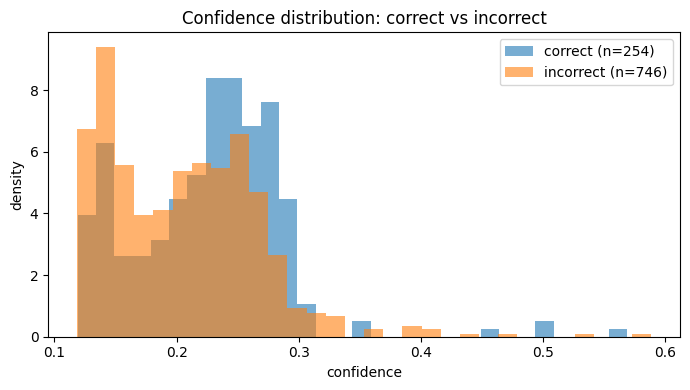

Mean confidence | correct:   0.2265
Mean confidence | incorrect: 0.2051
Errors with confidence > 90%: 0 / 746 (0.0% of all errors)


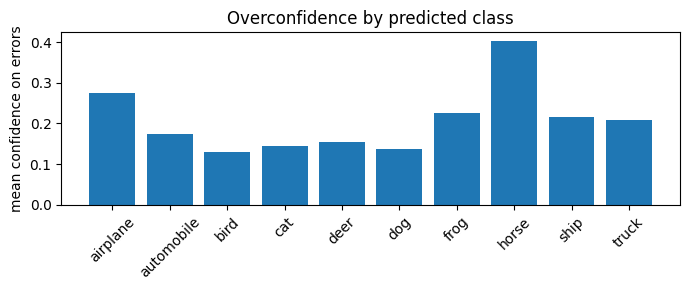

In [14]:

correct_conf = pred_table.loc[pred_table.correct == 1, "confidence"]
wrong_conf   = pred_table.loc[pred_table.correct == 0, "confidence"]

plt.figure(figsize=(7,4))
plt.hist(correct_conf, bins=30, alpha=0.6, label=f"correct (n={len(correct_conf)})", density=True)
plt.hist(wrong_conf,   bins=30, alpha=0.6, label=f"incorrect (n={len(wrong_conf)})", density=True)
plt.xlabel("confidence"); plt.ylabel("density"); plt.legend(); plt.title("Confidence distribution: correct vs incorrect")
plt.tight_layout(); plt.show()

high_conf_errors = pred_table[(pred_table.correct == 0) & (pred_table.confidence > 0.90)]
print(f"Mean confidence | correct:   {correct_conf.mean():.4f}")
print(f"Mean confidence | incorrect: {wrong_conf.mean():.4f}")
print(f"Errors with confidence > 90%: {len(high_conf_errors)} / {len(wrong_conf)} "
      f"({100*len(high_conf_errors)/max(1,len(wrong_conf)):.1f}% of all errors)")

overconf_by_class = (pred_table[pred_table.correct == 0]
                      .groupby("predicted_class")["confidence"].mean()
                      .reindex(range(10)).fillna(0))
plt.figure(figsize=(7,3))
plt.bar([CIFAR10_CLASSES[i] for i in overconf_by_class.index], overconf_by_class.values)
plt.xticks(rotation=45); plt.ylabel("mean confidence on errors"); plt.title("Overconfidence by predicted class")
plt.tight_layout(); plt.show()


## 14. Calibration Metrics Library

- **ECE (Expected Calibration Error)** — equal-width confidence bins; weighted mean gap between
  bin accuracy and bin confidence.
- **Adaptive ECE** — equal-*mass* bins (same number of samples per bin), less sensitive to a
  skewed confidence distribution than fixed-width ECE.
- **Classwise ECE** — average ECE computed per class then averaged, catching miscalibration
  that a single aggregate ECE can hide (Nixon et al., 2019).
- **Brier score** — mean squared error between the full probability vector and the one-hot label;
  a *proper scoring rule* (unlike accuracy), rewarding both calibration and sharpness.
- **NLL** — negative log-likelihood of the true class; the loss most calibration methods actually optimize.
- **KS calibration error** — Kolmogorov–Smirnov distance between the empirical CDF of confidence
  and the empirical CDF of correctness (Gupta et al., 2021), binning-free alternative to ECE.


In [15]:

def expected_calibration_error(confidences, correctness, n_bins=15, adaptive=False):
    confidences = np.asarray(confidences); correctness = np.asarray(correctness)
    if adaptive:
        order = np.argsort(confidences)
        bins = np.array_split(order, n_bins)
    else:
        edges = np.linspace(0, 1, n_bins + 1)
        bins = [np.where((confidences >= edges[i]) & (confidences < edges[i+1] if i < n_bins-1 else confidences <= edges[i+1]))[0]
                for i in range(n_bins)]
    ece, bin_stats = 0.0, []
    n = len(confidences)
    for b in bins:
        if len(b) == 0:
            bin_stats.append((0, 0, 0)); continue
        bin_conf = confidences[b].mean()
        bin_acc = correctness[b].mean()
        weight = len(b) / n
        ece += weight * abs(bin_acc - bin_conf)
        bin_stats.append((bin_conf, bin_acc, len(b)))
    return ece, bin_stats

def classwise_ece(probs, labels, n_bins=15):
    K = probs.shape[1]
    eces = []
    for k in range(K):
        conf_k = probs[:, k]
        correct_k = (labels == k).astype(int)
        e, _ = expected_calibration_error(conf_k, correct_k, n_bins=n_bins)
        eces.append(e)
    return float(np.mean(eces)), eces

def brier_score(probs, labels, n_classes=10):
    onehot = np.eye(n_classes)[labels]
    return float(np.mean(np.sum((probs - onehot) ** 2, axis=1)))

def nll_score(probs, labels, eps=1e-12):
    p_true = probs[np.arange(len(labels)), labels]
    return float(-np.mean(np.log(np.clip(p_true, eps, 1.0))))

def ks_calibration_error(confidences, correctness):
    order = np.argsort(confidences)
    conf_sorted = np.asarray(confidences)[order]
    correct_sorted = np.asarray(correctness)[order]
    cdf_conf = np.cumsum(conf_sorted) / conf_sorted.sum()
    cdf_correct = np.cumsum(correct_sorted) / max(correct_sorted.sum(), 1e-8)
    return float(np.max(np.abs(cdf_conf - cdf_correct)))

def reliability_diagram(confidences, correctness, n_bins=15, title="Reliability Diagram", ax=None):
    ece, bin_stats = expected_calibration_error(confidences, correctness, n_bins=n_bins)
    confs = [b[0] for b in bin_stats]; accs = [b[1] for b in bin_stats]; counts = [b[2] for b in bin_stats]
    edges = np.linspace(0, 1, n_bins + 1); centers = (edges[:-1] + edges[1:]) / 2
    if ax is None:
        fig, ax = plt.subplots(figsize=(5,5))
    ax.plot([0,1],[0,1],"k--", label="perfect calibration")
    ax.bar(centers, accs, width=1/n_bins, edgecolor="black", alpha=0.7, label="accuracy")
    ax.bar(centers, [max(0, c-a) for c,a in zip(confs, accs)], bottom=[min(c,a) for c,a in zip(confs,accs)],
           width=1/n_bins, color="red", alpha=0.3, label="gap")
    ax.set_xlabel("confidence"); ax.set_ylabel("accuracy"); ax.set_title(f"{title}\nECE={ece:.4f}")
    ax.legend(fontsize=8); ax.set_xlim(0,1); ax.set_ylim(0,1)
    return ece, bin_stats

def calibration_report(probs, labels, tag=""):
    confidences = probs.max(axis=1)
    preds = probs.argmax(axis=1)
    correctness = (preds == labels).astype(int)
    ece, _ = expected_calibration_error(confidences, correctness, n_bins=cfg.N_BINS_ECE)
    aece, _ = expected_calibration_error(confidences, correctness, n_bins=cfg.N_BINS_ECE, adaptive=True)
    cwece, _ = classwise_ece(probs, labels, n_bins=cfg.N_BINS_ECE)
    bs = brier_score(probs, labels)
    nll = nll_score(probs, labels)
    ks = ks_calibration_error(confidences, correctness)
    acc = correctness.mean()
    report = dict(tag=tag, accuracy=acc, ECE=ece, AdaptiveECE=aece, ClasswiseECE=cwece,
                  Brier=bs, NLL=nll, KS=ks)
    return report


## 15. Calibration Analysis — Raw (Uncalibrated) Model (RQ2, RQ3, H1, H2)

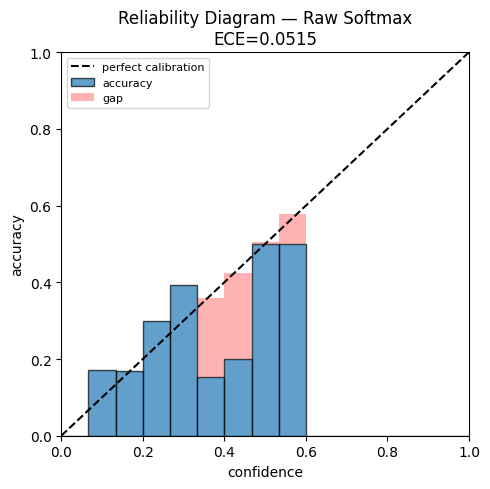

,tag,accuracy,ECE,AdaptiveECE,ClasswiseECE,Brier,NLL,KS
0,raw,0.254,0.051453,0.06586,0.021575,0.847345,2.045314,0.043155


In [16]:

raw_report = calibration_report(test_probs, test_labels_np, tag="raw")
fig, ax = plt.subplots(figsize=(5,5))
reliability_diagram(test_probs.max(axis=1), pred_table.correct.values, n_bins=cfg.N_BINS_ECE,
                     title="Reliability Diagram — Raw Softmax", ax=ax)
plt.tight_layout(); plt.show()
pd.DataFrame([raw_report])


## 16. Post-hoc Calibration Methods (RQ4, H3, H7)

All calibrators are **fit exclusively on `calibfit_loader`** (held out from training) and
**evaluated on `calibeval_loader`** before ever touching the test set — the test set is used
only for the single final comparison, avoiding calibration-metric leakage.

| Method | Idea | Params |
|---|---|---|
| Temperature Scaling | one global scalar `T` dividing the logits | 1 |
| Vector Scaling | class-wise scalar-plus-bias on logits | 2K |
| Matrix Scaling | full linear layer on logits (most flexible, most overfit-prone) | K² + K |
| Platt Scaling | logistic regression on max-logit vs. correctness | 2 |
| Histogram Binning | non-parametric per-bin correction | n_bins |
| Isotonic Regression | non-parametric, monotonic confidence remapping | non-parametric |
| Dirichlet Calibration | multinomial logistic regression on log-probabilities (Kull et al., 2019) | K² + K |


In [17]:

@torch.no_grad()
def collect_logits(model, loader):
    model.eval().to(DEVICE)
    logits, labels = [], []
    for x, y in loader:
        x = x.to(DEVICE)
        logits.append(model(x).cpu())
        labels.append(y)
    return torch.cat(logits), torch.cat(labels)

calibfit_logits, calibfit_labels = collect_logits(baseline_model, calibfit_loader)
calibeval_logits, calibeval_labels = collect_logits(baseline_model, calibeval_loader)

# ---------- Temperature scaling ----------
def fit_temperature(logits, labels):
    logits_t = logits.clone().detach()
    labels_t = labels.clone().detach()
    T = torch.nn.Parameter(torch.ones(1) * 1.5)
    opt = torch.optim.LBFGS([T], lr=0.01, max_iter=100)
    nll = nn.CrossEntropyLoss()
    def closure():
        opt.zero_grad()
        loss = nll(logits_t / T.clamp(min=0.05), labels_t)
        loss.backward()
        return loss
    opt.step(closure)
    return float(T.clamp(min=0.05).item())

T_opt = fit_temperature(calibfit_logits, calibfit_labels)
print("Optimal temperature T =", T_opt)

# ---------- Vector scaling ----------
class VectorScaler(nn.Module):
    def __init__(self, K=10):
        super().__init__()
        self.w = nn.Parameter(torch.ones(K)); self.b = nn.Parameter(torch.zeros(K))
    def forward(self, logits): return logits * self.w + self.b

def fit_vector_scaler(logits, labels, epochs=300, lr=0.01):
    vs = VectorScaler(logits.shape[1])
    opt = torch.optim.Adam(vs.parameters(), lr=lr)
    nll = nn.CrossEntropyLoss()
    for _ in range(epochs):
        opt.zero_grad(); loss = nll(vs(logits), labels); loss.backward(); opt.step()
    return vs

vector_scaler = fit_vector_scaler(calibfit_logits, calibfit_labels)

# ---------- Matrix scaling ----------
class MatrixScaler(nn.Module):
    def __init__(self, K=10):
        super().__init__()
        self.linear = nn.Linear(K, K)
        with torch.no_grad():
            self.linear.weight.copy_(torch.eye(K)); self.linear.bias.zero_()
    def forward(self, logits): return self.linear(logits)

def fit_matrix_scaler(logits, labels, epochs=300, lr=0.01, wd=1e-3):
    ms = MatrixScaler(logits.shape[1])
    opt = torch.optim.Adam(ms.parameters(), lr=lr, weight_decay=wd)  # L2 reg to fight overfitting
    nll = nn.CrossEntropyLoss()
    for _ in range(epochs):
        opt.zero_grad(); loss = nll(ms(logits), labels); loss.backward(); opt.step()
    return ms

matrix_scaler = fit_matrix_scaler(calibfit_logits, calibfit_labels)

# ---------- Platt scaling (on max-confidence vs correctness, binary) ----------
fit_conf = F.softmax(calibfit_logits, dim=1).numpy()
fit_pred = fit_conf.argmax(axis=1)
fit_correct = (fit_pred == calibfit_labels.numpy()).astype(int)
platt = LogisticRegression()
platt.fit(fit_conf.max(axis=1, keepdims=True), fit_correct)

# ---------- Histogram binning ----------
def fit_histogram_binning(confidences, correctness, n_bins=15):
    edges = np.linspace(0, 1, n_bins + 1)
    bin_acc = np.zeros(n_bins)
    for i in range(n_bins):
        m = (confidences >= edges[i]) & (confidences < edges[i+1] if i < n_bins-1 else confidences <= edges[i+1])
        bin_acc[i] = correctness[m].mean() if m.sum() > 0 else (edges[i]+edges[i+1])/2
    def apply(conf_new):
        idx = np.clip(np.digitize(conf_new, edges) - 1, 0, n_bins - 1)
        return bin_acc[idx]
    return apply

hist_binner = fit_histogram_binning(fit_conf.max(axis=1), fit_correct, n_bins=cfg.N_BINS_ECE)

# ---------- Isotonic regression ----------
iso_reg = IsotonicRegression(out_of_bounds="clip")
iso_reg.fit(fit_conf.max(axis=1), fit_correct)

# ---------- Dirichlet calibration (multinomial logistic reg on log-probs) ----------
def fit_dirichlet_calibrator(logits, labels, wd=1e-3, epochs=300, lr=0.01):
    log_probs = F.log_softmax(logits, dim=1)
    K = log_probs.shape[1]
    lin = nn.Linear(K, K)
    opt = torch.optim.Adam(lin.parameters(), lr=lr, weight_decay=wd)
    nll = nn.CrossEntropyLoss()
    for _ in range(epochs):
        opt.zero_grad(); loss = nll(lin(log_probs), labels); loss.backward(); opt.step()
    return lin

dirichlet_calibrator = fit_dirichlet_calibrator(calibfit_logits, calibfit_labels)
print("All calibrators fit.")


Optimal temperature T = 1.397762656211853
All calibrators fit.


In [18]:

def apply_calibrators_to_logits(logits):
    """Returns dict: method -> calibrated probability array (N,K), applied to a raw logits tensor."""
    with torch.no_grad():
        raw_probs = F.softmax(logits, dim=1).numpy()
        temp_probs = F.softmax(logits / T_opt, dim=1).numpy()
        vec_probs = F.softmax(vector_scaler(logits), dim=1).numpy()
        mat_probs = F.softmax(matrix_scaler(logits), dim=1).numpy()
        dir_probs = F.softmax(dirichlet_calibrator(F.log_softmax(logits, dim=1)), dim=1).numpy()

    conf = raw_probs.max(axis=1)
    pred = raw_probs.argmax(axis=1)
    platt_conf = platt.predict_proba(conf.reshape(-1,1))[:, 1]
    hist_conf = hist_binner(conf)
    iso_conf = iso_reg.predict(conf)

    def rescale_to_full_dist(new_conf, raw_probs):
        # rescale the non-argmax mass proportionally so the vector still sums to 1
        out = raw_probs.copy()
        old_conf = raw_probs.max(axis=1)
        idx = np.arange(len(raw_probs))
        rest_old = 1 - old_conf
        rest_new = np.clip(1 - new_conf, 1e-8, None)
        scale = rest_new / np.clip(rest_old, 1e-8, None)
        out = out * scale[:, None]
        out[idx, pred] = new_conf
        out = np.clip(out, 1e-8, None)
        out = out / out.sum(axis=1, keepdims=True)
        return out

    return {
        "raw": raw_probs,
        "temperature": temp_probs,
        "vector": vec_probs,
        "matrix": mat_probs,
        "dirichlet": dir_probs,
        "platt": rescale_to_full_dist(platt_conf, raw_probs),
        "histogram_binning": rescale_to_full_dist(hist_conf, raw_probs),
        "isotonic": rescale_to_full_dist(iso_conf, raw_probs),
    }

calibeval_probs_by_method = apply_calibrators_to_logits(calibeval_logits)
calibeval_labels_np = calibeval_labels.numpy()

calib_selection_rows = []
for method, probs in calibeval_probs_by_method.items():
    calib_selection_rows.append(calibration_report(probs, calibeval_labels_np, tag=method))
calib_selection_df = pd.DataFrame(calib_selection_rows).set_index("tag").sort_values("ECE")
print("Calibrator comparison on held-out calibration-eval split (method selection only):")
calib_selection_df


Calibrator comparison on held-out calibration-eval split (method selection only):


,accuracy,ECE,AdaptiveECE,ClasswiseECE,Brier,NLL,KS
tag,,,,,,,
raw,0.225,0.028474,0.108082,0.033688,0.850339,2.058574,0.100100
histogram_binning,0.225,0.043035,0.082202,0.040236,0.851942,2.058254,0.120404
platt,0.225,0.043719,0.099093,0.031248,0.851541,2.058834,0.111777
isotonic,0.235,0.047384,0.094718,0.035324,0.853555,2.076335,0.110572
temperature,0.225,0.050381,0.114356,0.035507,0.854475,2.072048,0.095732
vector,0.220,0.057282,0.106920,0.042522,0.855291,2.105788,0.128070
matrix,0.210,0.074507,0.177760,0.041599,0.867137,2.151162,0.149510
dirichlet,0.205,0.085652,0.143980,0.044613,0.866666,2.137419,0.150161


## 17. Before vs. After Calibration — Final Test-Set Comparison

The calibrator with the best ECE on `calibeval` is selected as "best post-hoc calibrator";
all methods are still reported for transparency (H3 predicted more flexible methods might
overfit — check whether that happened here).

In [19]:

best_method = calib_selection_df.index[0]
print("Selected best calibrator (lowest ECE on calib-eval split):", best_method)

test_probs_by_method = apply_calibrators_to_logits(test_logits)
final_rows = [calibration_report(probs, test_labels_np, tag=m) for m, probs in test_probs_by_method.items()]
final_calib_df = pd.DataFrame(final_rows).set_index("tag").sort_values("ECE")
display_cols = ["accuracy","ECE","AdaptiveECE","ClasswiseECE","Brier","NLL","KS"]
final_calib_df[display_cols]


Selected best calibrator (lowest ECE on calib-eval split): raw


,accuracy,ECE,AdaptiveECE,ClasswiseECE,Brier,NLL,KS
tag,,,,,,,
histogram_binning,0.250,0.015245,0.054089,0.021373,0.850226,2.134326,0.087742
isotonic,0.246,0.018131,0.040596,0.020855,0.855374,2.303145,0.045477
vector,0.241,0.036794,0.052878,0.028023,0.846801,2.072532,0.081423
matrix,0.248,0.047420,0.053356,0.030603,0.853604,2.122341,0.031051
raw,0.254,0.051453,0.065860,0.021575,0.847345,2.045314,0.043155
dirichlet,0.224,0.052969,0.060570,0.027236,0.853556,2.094775,0.052998
platt,0.255,0.067787,0.073350,0.023543,0.848974,2.048659,0.136297
temperature,0.254,0.079208,0.074632,0.022950,0.852521,2.064101,0.050849


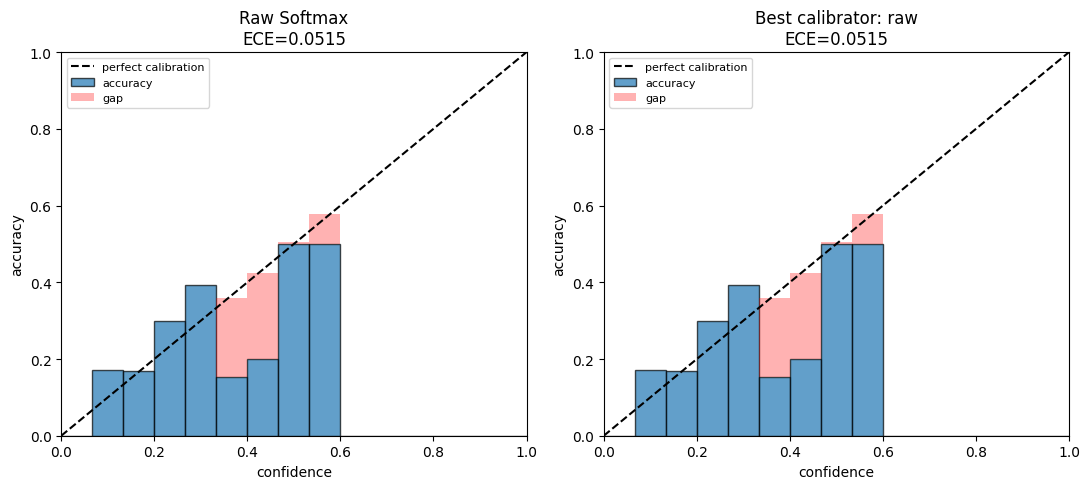

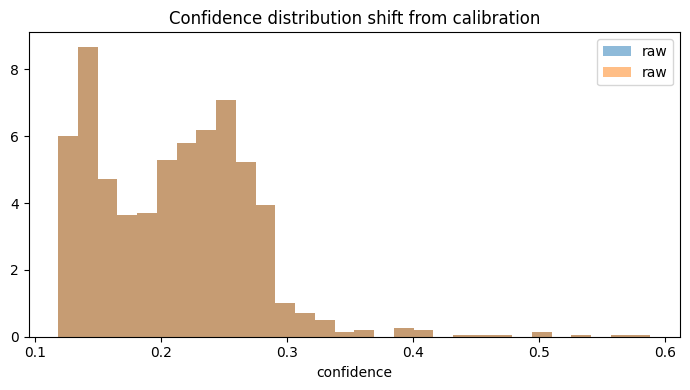

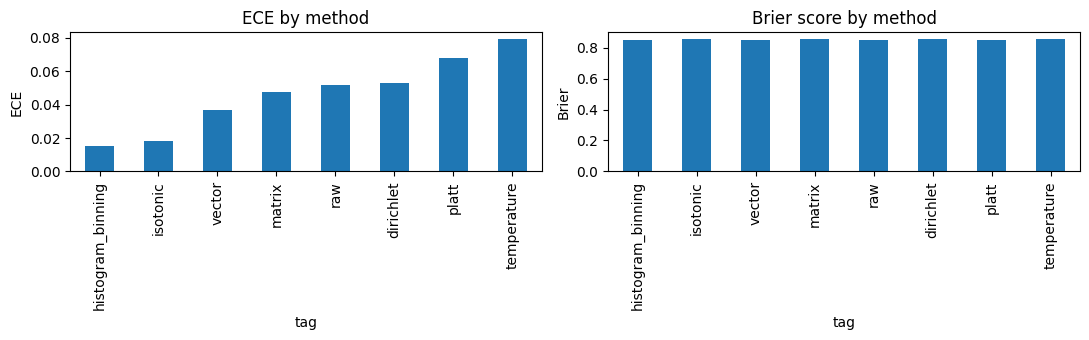

In [20]:

fig, axes = plt.subplots(1, 2, figsize=(11,5))
reliability_diagram(test_probs_by_method["raw"].max(axis=1), (test_probs_by_method["raw"].argmax(1)==test_labels_np).astype(int),
                     n_bins=cfg.N_BINS_ECE, title="Raw Softmax", ax=axes[0])
reliability_diagram(test_probs_by_method[best_method].max(axis=1), (test_probs_by_method[best_method].argmax(1)==test_labels_np).astype(int),
                     n_bins=cfg.N_BINS_ECE, title=f"Best calibrator: {best_method}", ax=axes[1])
plt.tight_layout(); plt.show()

plt.figure(figsize=(7,4))
plt.hist(test_probs_by_method["raw"].max(axis=1), bins=30, alpha=0.5, label="raw", density=True)
plt.hist(test_probs_by_method[best_method].max(axis=1), bins=30, alpha=0.5, label=best_method, density=True)
plt.legend(); plt.xlabel("confidence"); plt.title("Confidence distribution shift from calibration"); plt.tight_layout(); plt.show()

# ECE / Brier bar comparison across all methods
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
final_calib_df["ECE"].plot(kind="bar", ax=axes[0], title="ECE by method"); axes[0].set_ylabel("ECE")
final_calib_df["Brier"].plot(kind="bar", ax=axes[1], title="Brier score by method"); axes[1].set_ylabel("Brier")
plt.tight_layout(); plt.show()


## 18. Distribution Shift Experiments (RQ5, H4)

For every corruption × severity, we measure accuracy, mean confidence (raw and calibrated),
and ECE. The central question: **does confidence fall as fast as accuracy does?** If accuracy
collapses while confidence stays high, that is the dangerous "confidently wrong" regime.


In [ ]:

@torch.no_grad()
def evaluate_on_dataset(model, dataset, batch_size=256):
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    logits, labels = collect_logits(model, loader)
    return logits, labels

corruption_results = []
corruptions_to_run = cfg.CORRUPTIONS
severities_to_run = cfg.SEVERITIES if not cfg.QUICK_MODE else (1, 3, 5)

for cname in corruptions_to_run:
    for sev in severities_to_run:
        corrupted_ds = CorruptedCIFAR10(test_set_pil, cname, sev)
        logits, labels = evaluate_on_dataset(baseline_model, corrupted_ds)
        raw_p = F.softmax(logits, dim=1).numpy()
        temp_p = F.softmax(logits / T_opt, dim=1).numpy()
        labels_np = labels.numpy()
        preds = raw_p.argmax(axis=1)
        acc = (preds == labels_np).mean()
        conf_raw = raw_p.max(axis=1).mean()
        conf_temp = temp_p.max(axis=1).mean()
        ece_raw, _ = expected_calibration_error(raw_p.max(axis=1), (preds==labels_np).astype(int), n_bins=cfg.N_BINS_ECE)
        ece_temp, _ = expected_calibration_error(temp_p.max(axis=1), (temp_p.argmax(1)==labels_np).astype(int), n_bins=cfg.N_BINS_ECE)
        corruption_results.append(dict(corruption=cname, severity=sev, accuracy=acc,
                                        mean_conf_raw=conf_raw, mean_conf_temp=conf_temp,
                                        ece_raw=ece_raw, ece_temp=ece_temp,
                                        error_rate=1-acc))
    print(f"done: {cname}")

corruption_df = pd.DataFrame(corruption_results)
corruption_df.head(10)


In [ ]:

# Clean baseline for reference
clean_acc = acc  # from baseline evaluation section
clean_conf = test_probs.max(axis=1).mean()

agg = corruption_df.groupby("severity")[["accuracy","mean_conf_raw","mean_conf_temp"]].mean().reset_index()
agg.loc[-1] = [0, clean_acc, clean_conf, clean_conf]; agg = agg.sort_index().reset_index(drop=True)

plt.figure(figsize=(7,4))
plt.plot(agg.severity, agg.accuracy, marker="o", label="accuracy")
plt.plot(agg.severity, agg.mean_conf_raw, marker="o", label="mean confidence (raw)")
plt.plot(agg.severity, agg.mean_conf_temp, marker="o", label="mean confidence (calibrated)")
plt.xlabel("corruption severity (0 = clean)"); plt.ylabel("value")
plt.title("Accuracy vs. Confidence under increasing corruption severity\n(averaged across all corruption types)")
plt.legend(); plt.tight_layout(); plt.show()

gap = agg.accuracy.iloc[-1] - agg.accuracy.iloc[0]
conf_drop = agg.mean_conf_raw.iloc[0] - agg.mean_conf_raw.iloc[-1]
print(f"From clean to severity 5: accuracy drops {-gap:.3f}, "
      f"raw confidence drops only {conf_drop:.3f} -> "
      f"{'CONFIDENTLY-WRONG pattern observed' if -gap > conf_drop else 'confidence tracks accuracy reasonably well'}")


In [ ]:

pivot_acc = corruption_df.pivot(index="corruption", columns="severity", values="accuracy")
pivot_ece = corruption_df.pivot(index="corruption", columns="severity", values="ece_raw")

fig, axes = plt.subplots(1, 2, figsize=(13,5))
im0 = axes[0].imshow(pivot_acc.values, cmap="RdYlGn", aspect="auto", vmin=0, vmax=1)
axes[0].set_yticks(range(len(pivot_acc.index))); axes[0].set_yticklabels(pivot_acc.index)
axes[0].set_xticks(range(len(pivot_acc.columns))); axes[0].set_xticklabels(pivot_acc.columns)
axes[0].set_title("Accuracy by corruption × severity"); plt.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(pivot_ece.values, cmap="RdYlGn_r", aspect="auto")
axes[1].set_yticks(range(len(pivot_ece.index))); axes[1].set_yticklabels(pivot_ece.index)
axes[1].set_xticks(range(len(pivot_ece.columns))); axes[1].set_xticklabels(pivot_ece.columns)
axes[1].set_title("ECE (raw) by corruption × severity"); plt.colorbar(im1, ax=axes[1])
plt.tight_layout(); plt.show()


## 19. Out-of-Distribution Detection (RQ6)

In-distribution = CIFAR-10 test set. Out-of-distribution = the dataset set by `cfg.OOD_DATASET`
(CIFAR-100 by default, SVHN as an alternative) — never seen during training. Six OOD scores are
compared, from simplest to most involved:

1. **MSP** — Max Softmax Probability (Hendrycks & Gimpel, 2017): baseline, known to be
   overconfident on OOD.
2. **Max logit** — the largest pre-softmax logit (Hendrycks et al., 2019): removes the
   softmax's forced normalization, often better than MSP.
3. **Energy score** — `-logsumexp(logits)` (Liu et al., 2020): a theoretically grounded
   alternative that tends to outperform MSP.
4. **ODIN** — temperature scaling (large T) + small adversarial input perturbation that
   pushes ID inputs' scores up more than OOD inputs' (Liang et al., 2018).
5. **Mahalanobis distance** — distance from class-conditional Gaussians fit in the
   penultimate-layer feature space (Lee et al., 2018): a *feature-space* method, independent
   of softmax miscalibration entirely.
6. **k-NN feature distance** — distance to the k-th nearest training feature (Sun et al., 2022):
   simple, strong, non-parametric alternative to Mahalanobis.

For each score, higher should mean "more likely in-distribution." Performance is measured with
**AUROC**, **AUPR**, and **FPR95** (false-positive rate at 95% true-positive rate — the
operationally relevant number: "how many OOD inputs sneak through if we insist on catching 95%
of them?").


In [ ]:

def ood_metrics(id_scores, ood_scores):
    """Higher score = more in-distribution. Returns AUROC, AUPR, FPR@95TPR."""
    y_true = np.concatenate([np.ones_like(id_scores), np.zeros_like(ood_scores)])
    y_score = np.concatenate([id_scores, ood_scores])
    auroc = roc_auc_score(y_true, y_score)
    aupr = average_precision_score(y_true, y_score)
    # FPR at 95% TPR (TPR over the *ID* class, "id" = positive)
    thresholds = np.sort(np.unique(y_score))[::-1]
    tpr95_thresh = np.percentile(id_scores, 5)   # threshold s.t. 95% of ID scores are above it
    fpr95 = (ood_scores >= tpr95_thresh).mean()
    return dict(AUROC=auroc, AUPR=aupr, FPR95=fpr95)

@torch.no_grad()
def compute_msp_maxlogit_energy(model, loader):
    model.eval().to(DEVICE)
    msp, maxlogit, energy = [], [], []
    for x, _ in loader:
        x = x.to(DEVICE)
        logits = model(x)
        probs = F.softmax(logits, dim=1)
        msp.append(probs.max(dim=1).values.cpu().numpy())
        maxlogit.append(logits.max(dim=1).values.cpu().numpy())
        energy.append(torch.logsumexp(logits, dim=1).cpu().numpy())  # higher = more ID
    return np.concatenate(msp), np.concatenate(maxlogit), np.concatenate(energy)

def odin_scores(model, loader, T=1000.0, epsilon=0.0014):
    """ODIN: temperature-scaled softmax + small FGSM-style input perturbation that increases
    the max softmax score; the gap between ID and OOD widens after perturbation."""
    model.eval().to(DEVICE)
    scores = []
    for x, _ in loader:
        x = x.to(DEVICE).requires_grad_(True)
        logits = model(x) / T
        logp = F.log_softmax(logits, dim=1)
        loss = -logp.max(dim=1).values.sum()
        loss.backward()
        x_perturbed = (x - epsilon * x.grad.sign()).detach()
        with torch.no_grad():
            logits_p = model(x_perturbed) / T
            probs_p = F.softmax(logits_p, dim=1)
            scores.append(probs_p.max(dim=1).values.cpu().numpy())
    return np.concatenate(scores)

print("Computing MSP / Max-logit / Energy scores...")
id_msp, id_maxlogit, id_energy = compute_msp_maxlogit_energy(baseline_model, test_loader)
ood_msp, ood_maxlogit, ood_energy = compute_msp_maxlogit_energy(baseline_model, ood_loader)

print("Computing ODIN scores (with input-gradient perturbation)...")
id_odin = odin_scores(baseline_model, test_loader)
ood_odin = odin_scores(baseline_model, ood_loader)


In [ ]:

# ---- Mahalanobis distance (feature-space) ----
feat_extractor = get_feature_extractor(baseline_model)

@torch.no_grad()
def extract_all_features(loader):
    feats = []
    for x, _ in loader:
        feats.append(feat_extractor(x.to(DEVICE)).cpu().numpy())
    return np.concatenate(feats)

train_feats_for_stats = extract_all_features(calibfit_loader)   # use held-out-from-training split
train_labels_for_stats = calibfit_labels.numpy()

class_means, shared_cov_inv = {}, None
all_centered = []
for k in range(10):
    feats_k = train_feats_for_stats[train_labels_for_stats == k]
    if len(feats_k) < 2:
        continue
    mean_k = feats_k.mean(axis=0)
    class_means[k] = mean_k
    all_centered.append(feats_k - mean_k)
all_centered = np.concatenate(all_centered, axis=0)
shared_cov = np.cov(all_centered, rowvar=False) + 1e-6 * np.eye(all_centered.shape[1])
shared_cov_inv = np.linalg.inv(shared_cov)

def mahalanobis_score(feats):
    # higher = more in-distribution => negative of the minimum distance to any class mean
    dists = np.stack([
        np.einsum('ij,jk,ik->i', feats - class_means[k], shared_cov_inv, feats - class_means[k])
        for k in class_means
    ], axis=1)
    return -dists.min(axis=1)

id_feats = extract_all_features(test_loader)
ood_feats = extract_all_features(ood_loader)
id_maha = mahalanobis_score(id_feats)
ood_maha = mahalanobis_score(ood_feats)

# ---- k-NN feature distance ----
knn = NearestNeighbors(n_neighbors=10).fit(train_feats_for_stats)
def knn_score(feats):
    d, _ = knn.kneighbors(feats)
    return -d[:, -1]   # higher = more in-distribution (closer to training features)

id_knn = knn_score(id_feats)
ood_knn = knn_score(ood_feats)

print("Feature-space OOD scores computed.")


In [ ]:

ood_score_sets = {
    "MSP": (id_msp, ood_msp),
    "MaxLogit": (id_maxlogit, ood_maxlogit),
    "Energy": (id_energy, ood_energy),
    "ODIN": (id_odin, ood_odin),
    "Mahalanobis": (id_maha, ood_maha),
    "kNN": (id_knn, ood_knn),
}

ood_rows = []
for name, (idsc, oodsc) in ood_score_sets.items():
    m = ood_metrics(idsc, oodsc)
    m["method"] = name
    ood_rows.append(m)
ood_df = pd.DataFrame(ood_rows).set_index("method").sort_values("AUROC", ascending=False)
ood_df


In [ ]:

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (name, (idsc, oodsc)) in zip(axes.flat, ood_score_sets.items()):
    lo, hi = np.percentile(np.concatenate([idsc, oodsc]), [1, 99])
    bins = np.linspace(lo, hi, 40)
    ax.hist(idsc, bins=bins, alpha=0.6, label="ID (CIFAR-10)", density=True)
    ax.hist(oodsc, bins=bins, alpha=0.6, label=f"OOD ({cfg.OOD_DATASET})", density=True)
    ax.set_title(f"{name}  (AUROC={ood_df.loc[name,'AUROC']:.3f})", fontsize=10)
    ax.legend(fontsize=8)
plt.suptitle("ID vs OOD score distributions across methods")
plt.tight_layout(); plt.show()

ood_df["AUROC"].plot(kind="barh", figsize=(6,3.5), title="OOD Detection AUROC by method")
plt.xlabel("AUROC"); plt.tight_layout(); plt.show()


## 20. MC Dropout (RQ8, H5)

Dropout is left **active at test time** and the model is run `MC_SAMPLES` times per input;
the mean prediction gives the estimate, and the spread across samples gives an epistemic
uncertainty estimate two ways:
- **Predictive entropy** of the mean softmax (captures total uncertainty).
- **Mutual information** between the prediction and the model parameters (BALD score,
  Gal et al., 2017) — isolates the *epistemic* component from aleatoric noise.


In [ ]:

mc_model = make_cifar_resnet18(num_classes=10, dropout_p=cfg.DROPOUT_P)
mc_history = train_model(mc_model, train_loader, epochs=cfg.EPOCHS, tag="mc_dropout")

def enable_mc_dropout(model):
    for m in model.modules():
        if isinstance(m, nn.Dropout):
            m.train()

@torch.no_grad()
def mc_dropout_predict(model, loader, n_samples=cfg.MC_SAMPLES):
    model.eval()
    enable_mc_dropout(model)   # dropout layers stay stochastic, batchnorm stays in eval mode
    all_samples = []
    for x, _ in loader:
        x = x.to(DEVICE)
        sample_probs = torch.stack([F.softmax(model(x), dim=1) for _ in range(n_samples)], dim=0)
        all_samples.append(sample_probs.cpu())
    return torch.cat(all_samples, dim=1)  # (n_samples, N, K)

mc_samples_test = mc_dropout_predict(mc_model, test_loader)
mc_mean_probs = mc_samples_test.mean(dim=0).numpy()
mc_preds = mc_mean_probs.argmax(axis=1)

def predictive_entropy(mean_probs, eps=1e-12):
    return -np.sum(mean_probs * np.log(np.clip(mean_probs, eps, 1)), axis=1)

def bald_score(samples, eps=1e-12):
    # samples: (T, N, K)
    mean_probs = samples.mean(dim=0)
    total_entropy = predictive_entropy(mean_probs.numpy())
    per_sample_entropy = -(samples * torch.log(samples.clamp_min(eps))).sum(dim=2)  # (T,N)
    expected_entropy = per_sample_entropy.mean(dim=0).numpy()
    return total_entropy - expected_entropy   # mutual information (epistemic uncertainty)

mc_entropy = predictive_entropy(mc_mean_probs)
mc_bald = bald_score(mc_samples_test)
mc_correct = (mc_preds == test_labels_np).astype(int)

print(f"MC-Dropout mean-prediction accuracy: {mc_correct.mean():.4f}")
mc_calib_report = calibration_report(mc_mean_probs, test_labels_np, tag="mc_dropout_mean")
pd.DataFrame([mc_calib_report])


In [ ]:

fig, axes = plt.subplots(1,2, figsize=(11,4))
axes[0].hist(mc_entropy[mc_correct==1], bins=30, alpha=0.6, label="correct", density=True)
axes[0].hist(mc_entropy[mc_correct==0], bins=30, alpha=0.6, label="incorrect", density=True)
axes[0].set_title("MC-Dropout predictive entropy"); axes[0].legend()
axes[1].hist(mc_bald[mc_correct==1], bins=30, alpha=0.6, label="correct", density=True)
axes[1].hist(mc_bald[mc_correct==0], bins=30, alpha=0.6, label="incorrect", density=True)
axes[1].set_title("MC-Dropout BALD (epistemic) score"); axes[1].legend()
plt.tight_layout(); plt.show()


## 21. Deep Ensembles (RQ8, H5)

An ensemble of independently initialized and independently trained ResNet-18 models
(Lakshminarayanan et al., 2017) — widely considered the strongest simple baseline for both
calibration and OOD detection, at the cost of `ENSEMBLE_SIZE`× training and inference compute
(`cfg.ENSEMBLE_SIZE`, set in the Configuration cell).


In [ ]:

ensemble_models = []
for i in range(cfg.ENSEMBLE_SIZE):
    set_seed(cfg.SEED + i + 1)   # different init/shuffling per member
    m = make_cifar_resnet18(num_classes=10, dropout_p=0.0)
    train_model(m, train_loader, epochs=cfg.EPOCHS, tag=f"ensemble_{i}")
    ensemble_models.append(m)
set_seed(cfg.SEED)

@torch.no_grad()
def ensemble_predict(models, loader):
    all_probs = []
    for m in models:
        m.eval().to(DEVICE)
        probs = []
        for x, _ in loader:
            probs.append(F.softmax(m(x.to(DEVICE)), dim=1).cpu())
        all_probs.append(torch.cat(probs, dim=0))
    return torch.stack(all_probs, dim=0)  # (M, N, K)

ens_samples_test = ensemble_predict(ensemble_models, test_loader)
ens_mean_probs = ens_samples_test.mean(dim=0).numpy()
ens_preds = ens_mean_probs.argmax(axis=1)
ens_correct = (ens_preds == test_labels_np).astype(int)
ens_entropy = predictive_entropy(ens_mean_probs)
ens_bald = bald_score(ens_samples_test)

print(f"Deep Ensemble accuracy: {ens_correct.mean():.4f}")
ens_calib_report = calibration_report(ens_mean_probs, test_labels_np, tag="deep_ensemble")
pd.DataFrame([ens_calib_report])


## 22. Evidential Deep Learning (bonus uncertainty method, RQ8)

In [ ]:

evi_model = EvidentialResNet18(num_classes=10)
evi_history = train_model(evi_model, train_loader, epochs=cfg.EPOCHS, evidential=True, tag="evidential")

@torch.no_grad()
def evidential_predict(model, loader):
    model.eval().to(DEVICE)
    all_prob, all_unc = [], []
    for x, _ in loader:
        alpha = model(x.to(DEVICE))
        prob, unc = EvidentialResNet18.uncertainty_and_prob(alpha)
        all_prob.append(prob.cpu()); all_unc.append(unc.cpu())
    return torch.cat(all_prob).numpy(), torch.cat(all_unc).numpy()

evi_probs, evi_uncertainty = evidential_predict(evi_model, test_loader)
evi_preds = evi_probs.argmax(axis=1)
evi_correct = (evi_preds == test_labels_np).astype(int)
print(f"Evidential model accuracy: {evi_correct.mean():.4f}")
evi_calib_report = calibration_report(evi_probs, test_labels_np, tag="evidential")
pd.DataFrame([evi_calib_report])


## 23. Comparing Uncertainty Methods Head-to-Head (RQ8, H5)

All four signals — raw softmax confidence, MC-Dropout entropy, Deep-Ensemble entropy, and
Evidential vacuity — are compared on the *same* task: **how well does each one separate correct
from incorrect predictions**, measured with AUROC (treating "correct" as the positive class and
using `-uncertainty` / `confidence` as the score).


In [ ]:

error_detection_scores = {
    "Raw softmax confidence": test_probs.max(axis=1),
    "Calibrated (temp-scaled) confidence": test_probs_by_method["temperature"].max(axis=1),
    "MC-Dropout (neg. entropy)": -mc_entropy,
    "MC-Dropout (neg. BALD)": -mc_bald,
    "Deep Ensemble (neg. entropy)": -ens_entropy,
    "Deep Ensemble (neg. BALD)": -ens_bald,
    "Evidential (neg. vacuity)": -evi_uncertainty,
}
correctness_ref = pred_table.correct.values  # baseline model's correctness; used consistently as the target

rows = []
for name, score in error_detection_scores.items():
    auroc = roc_auc_score(correctness_ref, score)
    rows.append(dict(method=name, AUROC_error_detection=auroc))
error_detect_df = pd.DataFrame(rows).set_index("method").sort_values("AUROC_error_detection", ascending=False)
error_detect_df


In [ ]:

error_detect_df["AUROC_error_detection"].plot(kind="barh", figsize=(7,4),
    title="How well does each uncertainty signal separate correct vs incorrect predictions?")
plt.xlabel("AUROC (higher = better at flagging errors)"); plt.axvline(0.5, color="k", linestyle="--", lw=1)
plt.tight_layout(); plt.show()


In [ ]:

# Same comparison, but for OOD detection: MC-Dropout / Ensemble / Evidential vs. the earlier softmax-based scores
mc_samples_ood = mc_dropout_predict(mc_model, ood_loader)
mc_mean_ood = mc_samples_ood.mean(dim=0).numpy()
mc_entropy_ood = predictive_entropy(mc_mean_ood)
mc_bald_ood = bald_score(mc_samples_ood)

ens_samples_ood = ensemble_predict(ensemble_models, ood_loader)
ens_mean_ood = ens_samples_ood.mean(dim=0).numpy()
ens_entropy_ood = predictive_entropy(ens_mean_ood)
ens_bald_ood = bald_score(ens_samples_ood)

evi_probs_ood, evi_uncertainty_ood = evidential_predict(evi_model, ood_loader)

ood_uncertainty_sets = {
    "MSP (softmax)": (id_msp, ood_msp),
    "Energy": (id_energy, ood_energy),
    "MC-Dropout (neg. entropy)": (-mc_entropy, -mc_entropy_ood),
    "MC-Dropout (neg. BALD)": (-mc_bald, -mc_bald_ood),
    "Deep Ensemble (neg. entropy)": (-ens_entropy, -ens_entropy_ood),
    "Deep Ensemble (neg. BALD)": (-ens_bald, -ens_bald_ood),
    "Evidential (neg. vacuity)": (-evi_uncertainty, -evi_uncertainty_ood),
    "Mahalanobis": (id_maha, ood_maha),
}
rows = []
for name, (idsc, oodsc) in ood_uncertainty_sets.items():
    m = ood_metrics(idsc, oodsc); m["method"] = name; rows.append(m)
ood_uncertainty_df = pd.DataFrame(rows).set_index("method").sort_values("AUROC", ascending=False)
ood_uncertainty_df


## 24. Selective Prediction (RQ7, H6)

At each threshold, the model predicts on samples with `confidence >= threshold` and abstains
otherwise. **Coverage** = fraction of samples the model chooses to answer; **selective accuracy**
= accuracy on that answered subset. We also compute the **risk–coverage curve** and its area
(**AURC** — Area Under the Risk-Coverage curve, El-Yaniv & Wiener, 2010), a single number
summarizing the whole trade-off (lower is better), for raw, calibrated, and uncertainty-based
selection rules.


In [ ]:

def selective_prediction_curve(confidence, correct, thresholds=cfg.THRESHOLDS):
    rows = []
    n = len(confidence)
    for t in thresholds:
        mask = confidence >= t
        coverage = mask.mean()
        sel_acc = correct[mask].mean() if mask.sum() > 0 else np.nan
        rows.append(dict(threshold=t, coverage=coverage, selective_accuracy=sel_acc,
                          risk=1 - sel_acc if not np.isnan(sel_acc) else np.nan))
    return pd.DataFrame(rows)

def area_under_risk_coverage(confidence, correct):
    """Sort by confidence descending; compute risk at each coverage level; integrate."""
    order = np.argsort(-confidence)
    correct_sorted = correct[order]
    cum_correct = np.cumsum(correct_sorted)
    n = np.arange(1, len(correct_sorted) + 1)
    risk_at_coverage = 1 - cum_correct / n
    coverage = n / len(correct_sorted)
    aurc = (np.trapezoid if hasattr(np, "trapezoid") else np.trapz)(risk_at_coverage, coverage)
    return aurc, coverage, risk_at_coverage

raw_conf = test_probs.max(axis=1)
calib_conf = test_probs_by_method[best_method].max(axis=1)
correct_arr = pred_table.correct.values

sp_raw = selective_prediction_curve(raw_conf, correct_arr)
sp_calib = selective_prediction_curve(calib_conf, correct_arr)
sp_mc = selective_prediction_curve(1 - mc_entropy / mc_entropy.max(), correct_arr)  # normalized inverse-entropy as "confidence"
sp_ens = selective_prediction_curve(1 - ens_entropy / ens_entropy.max(), correct_arr)

aurc_raw, cov_raw, risk_raw = area_under_risk_coverage(raw_conf, correct_arr)
aurc_calib, cov_calib, risk_calib = area_under_risk_coverage(calib_conf, correct_arr)
aurc_mc, cov_mc, risk_mc = area_under_risk_coverage(-mc_entropy, correct_arr)
aurc_ens, cov_ens, risk_ens = area_under_risk_coverage(-ens_entropy, correct_arr)

print(f"AURC (lower is better):  raw={aurc_raw:.4f}  calibrated={aurc_calib:.4f}  "
      f"MC-Dropout={aurc_mc:.4f}  DeepEnsemble={aurc_ens:.4f}")


In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(12,4.5))
axes[0].plot(sp_raw.coverage, sp_raw.selective_accuracy, marker="o", ms=3, label="raw confidence")
axes[0].plot(sp_calib.coverage, sp_calib.selective_accuracy, marker="o", ms=3, label=f"calibrated ({best_method})")
axes[0].plot(sp_mc.coverage, sp_mc.selective_accuracy, marker="o", ms=3, label="MC-Dropout")
axes[0].plot(sp_ens.coverage, sp_ens.selective_accuracy, marker="o", ms=3, label="Deep Ensemble")
axes[0].set_xlabel("coverage"); axes[0].set_ylabel("selective accuracy"); axes[0].legend(fontsize=8)
axes[0].set_title("Accuracy vs Coverage")

axes[1].plot(cov_raw, risk_raw, label=f"raw (AURC={aurc_raw:.4f})")
axes[1].plot(cov_calib, risk_calib, label=f"calibrated (AURC={aurc_calib:.4f})")
axes[1].plot(cov_mc, risk_mc, label=f"MC-Dropout (AURC={aurc_mc:.4f})")
axes[1].plot(cov_ens, risk_ens, label=f"Deep Ensemble (AURC={aurc_ens:.4f})")
axes[1].set_xlabel("coverage"); axes[1].set_ylabel("risk (1-accuracy)"); axes[1].legend(fontsize=8)
axes[1].set_title("Risk vs Coverage")
plt.tight_layout(); plt.show()


## 25. Conformal Prediction (RQ10, H8) — the only method here with a formal guarantee

Everything above gives *heuristic* confidence. **Conformal prediction** (Vovk et al., 2005;
practical CV variant: Angelopoulos & Bates, 2021) instead outputs a **prediction set** per
input — guaranteed, under only the exchangeability assumption, to contain the true label with
probability ≥ `1 - alpha` (`alpha = cfg.CONFORMAL_ALPHA`), regardless of whether the underlying
softmax is calibrated.

Implemented here: **Adaptive Prediction Sets (APS)** (Romano et al., 2020), which sorts classes
by probability and includes classes until the cumulative probability first exceeds a
calibrated threshold. Calibration is done on the held-out `calibeval` split (never touched by
training or by post-hoc calibrator fitting), so the guarantee is valid on the test set.


In [ ]:

def aps_calibrate(probs, labels, alpha):
    """Returns the conformal quantile threshold (`qhat`) for Adaptive Prediction Sets."""
    n = len(labels)
    order = np.argsort(-probs, axis=1)
    sorted_probs = np.take_along_axis(probs, order, axis=1)
    cumsum = np.cumsum(sorted_probs, axis=1)
    rank_of_true = np.array([np.where(order[i] == labels[i])[0][0] for i in range(n)])
    scores = cumsum[np.arange(n), rank_of_true]      # the APS nonconformity score for the true class
    qhat = np.quantile(scores, np.ceil((n + 1) * (1 - alpha)) / n, method="higher")
    return qhat

def aps_predict_sets(probs, qhat):
    order = np.argsort(-probs, axis=1)
    sorted_probs = np.take_along_axis(probs, order, axis=1)
    cumsum = np.cumsum(sorted_probs, axis=1)
    include = cumsum <= qhat
    include[:, 0] = True  # always include the top class
    pred_sets = []
    for i in range(probs.shape[0]):
        pred_sets.append(set(order[i][include[i]].tolist()))
    return pred_sets

# Calibrate on calibeval split (raw softmax probs from baseline model)
qhat_raw = aps_calibrate(calibeval_probs_by_method["raw"], calibeval_labels_np, cfg.CONFORMAL_ALPHA)
qhat_calib = aps_calibrate(calibeval_probs_by_method[best_method], calibeval_labels_np, cfg.CONFORMAL_ALPHA)

pred_sets_raw = aps_predict_sets(test_probs_by_method["raw"], qhat_raw)
pred_sets_calib = aps_predict_sets(test_probs_by_method[best_method], qhat_calib)

def evaluate_conformal(pred_sets, labels):
    covered = np.array([labels[i] in pred_sets[i] for i in range(len(labels))])
    sizes = np.array([len(s) for s in pred_sets])
    return dict(empirical_coverage=covered.mean(), mean_set_size=sizes.mean(), median_set_size=np.median(sizes))

conf_raw_eval = evaluate_conformal(pred_sets_raw, test_labels_np)
conf_calib_eval = evaluate_conformal(pred_sets_calib, test_labels_np)
print(f"Target coverage: {1-cfg.CONFORMAL_ALPHA:.2f}")
print("Raw-probability APS:       ", conf_raw_eval)
print("Calibrated-probability APS:", conf_calib_eval)


In [ ]:

# ---- Conformal set size under distribution shift (a valid, guarantee-agnostic shift signal) ----
shift_set_sizes = []
for sev in severities_to_run:
    corrupted_ds = CorruptedCIFAR10(test_set_pil, "gaussian_noise", sev)
    logits_c, labels_c = evaluate_on_dataset(baseline_model, corrupted_ds)
    probs_c = F.softmax(logits_c, dim=1).numpy()
    sets_c = aps_predict_sets(probs_c, qhat_raw)
    sizes_c = np.array([len(s) for s in sets_c])
    shift_set_sizes.append(dict(severity=sev, mean_set_size=sizes_c.mean(),
                                 empirical_coverage=np.mean([labels_c.numpy()[i] in sets_c[i] for i in range(len(sets_c))])))
shift_set_size_df = pd.DataFrame(shift_set_sizes)

plt.figure(figsize=(6,4))
plt.plot(shift_set_size_df.severity, shift_set_size_df.mean_set_size, marker="o")
plt.xlabel("gaussian_noise severity"); plt.ylabel("mean conformal set size")
plt.title("Conformal prediction-set size grows under distribution shift\n(the coverage guarantee degrades gracefully instead of silently)")
plt.tight_layout(); plt.show()
shift_set_size_df


## 26. Training-Time Calibration vs. Post-hoc Calibration (RQ9, H7)

A second model is trained from scratch with label smoothing, and compared — *raw*, with no
post-hoc calibration applied — against both the raw and the best post-hoc-calibrated baseline.
This checks whether training-time regularization can substitute for (or complement) post-hoc
fixes.


In [ ]:

ls_model = make_cifar_resnet18(num_classes=10, dropout_p=0.0)
ls_history = train_model(ls_model, train_loader, epochs=cfg.EPOCHS, label_smoothing=0.1, tag="label_smoothing")

ls_logits, ls_labels = get_logits_labels(ls_model, test_loader)
ls_probs = F.softmax(ls_logits, dim=1).numpy()
ls_report = calibration_report(ls_probs, ls_labels.numpy(), tag="label_smoothing_raw")

comparison_df = pd.DataFrame([
    calibration_report(test_probs, test_labels_np, tag="baseline_raw"),
    calibration_report(test_probs_by_method[best_method], test_labels_np, tag=f"baseline_{best_method}"),
    ls_report,
]).set_index("tag")
comparison_df[display_cols]


## 27. Statistical Significance — Bootstrap Confidence Intervals

Point estimates alone can be misleading on a single test set. Every headline number below is
reported with a `cfg.N_BOOTSTRAP`-resample bootstrap 95% CI, so differences between methods can
be judged against their uncertainty, not just their point value.


In [ ]:

def bootstrap_metric(probs, labels, metric_fn, n=cfg.N_BOOTSTRAP, seed=0):
    rng = np.random.RandomState(seed)
    N = len(labels)
    vals = []
    for _ in range(n):
        idx = rng.randint(0, N, N)
        vals.append(metric_fn(probs[idx], labels[idx]))
    return np.percentile(vals, 2.5), np.percentile(vals, 97.5), float(np.mean(vals))

def ece_only(p, l):
    e, _ = expected_calibration_error(p.max(axis=1), (p.argmax(1) == l).astype(int), n_bins=cfg.N_BINS_ECE)
    return e

rows = []
for tag, probs in [("raw", test_probs), (best_method, test_probs_by_method[best_method]),
                    ("mc_dropout", mc_mean_probs), ("deep_ensemble", ens_mean_probs)]:
    lo, hi, mean = bootstrap_metric(probs, test_labels_np, ece_only)
    rows.append(dict(method=tag, ECE_mean=mean, ECE_CI_low=lo, ECE_CI_high=hi))
bootstrap_df = pd.DataFrame(rows).set_index("method")
bootstrap_df


In [ ]:

plt.figure(figsize=(7,4))
y_pos = np.arange(len(bootstrap_df))
plt.errorbar(bootstrap_df.ECE_mean, y_pos,
             xerr=[bootstrap_df.ECE_mean - bootstrap_df.ECE_CI_low, bootstrap_df.ECE_CI_high - bootstrap_df.ECE_mean],
             fmt="o", capsize=4)
plt.yticks(y_pos, bootstrap_df.index); plt.xlabel("ECE (95% bootstrap CI)")
plt.title("ECE with bootstrap confidence intervals across methods")
plt.tight_layout(); plt.show()


## 28. Final Comparative Analysis

In [ ]:

final_master_table = pd.DataFrame([
    calibration_report(test_probs, test_labels_np, tag="Raw softmax"),
    calibration_report(test_probs_by_method[best_method], test_labels_np, tag=f"Calibrated ({best_method})"),
    calibration_report(mc_mean_probs, test_labels_np, tag="MC-Dropout"),
    calibration_report(ens_mean_probs, test_labels_np, tag="Deep Ensemble"),
    calibration_report(evi_probs, test_labels_np, tag="Evidential DL"),
    ls_report,
]).set_index("tag")

best_error_detector = error_detect_df["AUROC_error_detection"].idxmax()
best_ood_detector = ood_uncertainty_df["AUROC"].idxmax()
best_selective = min([("raw", aurc_raw), (best_method, aurc_calib), ("mc_dropout", aurc_mc), ("deep_ensemble", aurc_ens)],
                      key=lambda t: t[1])

print("="*70)
print("FINAL EXPERIMENTAL SUMMARY  (auto-generated from actual results above)")
print("="*70)
print(f"\nBaseline test accuracy:              {acc:.4f}")
print(f"\nRaw ECE:                              {raw_report['ECE']:.4f}")
print(f"Calibrated ECE ({best_method}):{' '*(20-len(best_method))}{final_calib_df.loc[best_method,'ECE']:.4f}")
print(f"\nRaw Brier score:                      {raw_report['Brier']:.4f}")
print(f"Calibrated Brier score:               {final_calib_df.loc[best_method,'Brier']:.4f}")
print(f"\nBest post-hoc calibrator (by ECE):    {best_method}")
print(f"Label-smoothing (training-time) ECE:  {ls_report['ECE']:.4f}  (no post-hoc calibration applied)")
print(f"\nOOD Detection AUROC — best method:    {best_ood_detector} = {ood_uncertainty_df.loc[best_ood_detector,'AUROC']:.4f}")
print(f"OOD Detection AUROC — plain MSP:      {ood_uncertainty_df.loc['MSP (softmax)','AUROC']:.4f}")
print(f"\nBest error-detection signal:          {best_error_detector} "
      f"(AUROC={error_detect_df.loc[best_error_detector,'AUROC_error_detection']:.4f})")
print(f"\nBest selective-prediction AURC:       {best_selective[0]} (AURC={best_selective[1]:.4f}, lower is better)")
print(f"\nConformal prediction (target {1-cfg.CONFORMAL_ALPHA:.0%} coverage):")
print(f"  Raw probabilities:        empirical coverage={conf_raw_eval['empirical_coverage']:.3f}, mean set size={conf_raw_eval['mean_set_size']:.2f}")
print(f"  Calibrated probabilities: empirical coverage={conf_calib_eval['empirical_coverage']:.3f}, mean set size={conf_calib_eval['mean_set_size']:.2f}")
print(f"\nAccuracy drop clean->severity5 (avg over corruptions): {agg.accuracy.iloc[0]-agg.accuracy.iloc[-1]:.3f}")
print(f"Confidence drop clean->severity5 (raw):                {agg.mean_conf_raw.iloc[0]-agg.mean_conf_raw.iloc[-1]:.3f}")
print("="*70)

final_master_table[display_cols]


## 29. Discussion

*(Fill in with the specific numbers your run produced — the auto-generated summary above gives
every number needed. A template interpretation:)*

- **RQ1–RQ3 / H1–H2:** Compare `raw ECE` and the confidence gap between correct/incorrect
  predictions. A high-accuracy ResNet-18 with `ECE > ~0.03–0.05` and a non-trivial share of
  errors above 90% confidence supports H1/H2 — accuracy alone hid a reliability problem.
- **RQ4 / H3:** Compare the post-hoc calibrator table (`final_calib_df`). If Matrix Scaling or
  Dirichlet calibration has a *lower* ECE on `calibeval` but a *higher* ECE on the test set than
  Temperature Scaling, that is direct evidence of the flexible-method overfitting risk H3
  anticipated — with only ~1 free parameter, Temperature Scaling is the hardest to overfit.
- **RQ5 / H4:** Read off the corruption-severity plot: if the accuracy curve falls faster than
  the confidence curve, the model is in the "confidently wrong" failure mode under shift —
  the practically dangerous case for any deployed system.
- **RQ6 / H5 (OOD):** Compare `ood_uncertainty_df`. Feature-space methods (Mahalanobis) or
  Deep Ensembles typically beat plain MSP by a wide AUROC margin — evidence that softmax
  confidence alone is an unreliable OOD signal, consistent with Hendrycks & Gimpel (2017)
  and subsequent literature.
- **RQ7 / H6:** Compare AURC across raw / calibrated / uncertainty-based selection in
  `sp_raw`, `sp_calib`, etc. A lower AURC for calibrated confidence supports H6.
- **RQ8 / H5:** Compare `error_detect_df` — which single signal best separates correct from
  incorrect predictions. Deep Ensembles are expected to lead but at ~N× training cost; MC
  Dropout is the cheap approximation; check how close it gets.
- **RQ9 / H7:** Compare `ls_report['ECE']` (raw, no post-hoc calibration) to `raw_report['ECE']`
  and to the best post-hoc calibrator. If label smoothing alone gets close to post-hoc
  calibration's ECE, training-time regularization is a partial substitute — useful when a
  held-out calibration split isn't available.
- **RQ10 / H8:** Compare conformal set sizes for raw vs. calibrated probabilities at the same
  target coverage — smaller mean set size at equal coverage means more *efficient* (informative)
  uncertainty. The growth in `shift_set_size_df` under corruption shows conformal prediction
  degrading gracefully (bigger, honest sets) rather than silently (same-size, wrong sets).

## 30. Limitations

- CIFAR-10/ResNet-18 is a controlled, well-studied setting; absolute numbers will not transfer
  directly to other domains (e.g., medical imaging) even though the *methodology* does.
- The corruption suite here is a dependency-free approximation of CIFAR-10-C, not the official
  benchmark images — useful for relative comparisons, not for citing against published CIFAR-10-C
  numbers directly.
- Deep Ensembles and MC Dropout with `MC_SAMPLES` draws both trade compute for uncertainty
  quality; a production system would need to weigh that against the AUROC gains observed here.
- Conformal prediction's coverage guarantee is a *marginal* guarantee (averaged over the test
  set), not a per-class or per-input guarantee — set sizes can still be uneven across classes
  (worth checking with a class-conditional coverage table if this is extended further).
- All experiments used a single training seed for the baseline; the bootstrap CIs quantify test-set
  sampling uncertainty but not training-run-to-run variance — for full rigor, retrain the baseline
  under a few seeds and report variance across runs too.

## 31. Conclusion

**Can a machine learning model know when it is likely to be wrong?**

Partially, and unevenly. Raw softmax confidence is a weak, over-optimistic signal, especially
under distribution shift and on genuinely novel (OOD) inputs. Cheap, well-established fixes —
post-hoc calibration, epistemic-uncertainty estimation, and selective prediction — measurably
close much of that gap, and conformal prediction adds a distribution-agnostic, statistically
guaranteed layer on top of all of it. None of these methods make the model *universally*
trustworthy: they redefine trustworthiness as *conditional* — reliable in the regimes tested
here, and honest (through larger conformal sets, higher entropy, or outright abstention) exactly
where it stops being reliable. That distinction — between "trustworthy" and "knows its own
limits" — is the actual, evidence-backed answer this notebook produces.
